<html>
    <div>
        <span style="float: left; font-size: 120%; font-variant: small-caps;">
            Université Paul Sabatier
        </span>
        <span style="float: right; font-size: 120%;">
            Analyse de Fourier et théorie du signal
        </span>
    </div><br><br>
    <div align="center" style="font-size: 300%; font-weight: bold;">
        TP4
    </div>
</html>

# Théorie de l’échantillonnage

In [ ]:
%pylab inline
from imtoolsJeff import *
from numpy import *

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## Exercice 1 – Filtre d’échantillonnage de Shannon

On rappelle que lors du sous-échantillonnage d'une image numérique, le filtre de Shannon consiste à supprimer toutes les fréquences supérieures à la fréquence maximale de la transformée de Fourier de la nouvelle image.

1.  Implémenter une fonction `undersample1(u, K)` qui renvoie l'image $u$ sous-échantillonnée d'un facteur $K$ sans filtrage préalable. Rappeler pourquoi il est nécessaire de filtrer l'image avant échantillonnage, et générer un exemple d'image sur lequel le phénomène est visible.

<div style="color:blue"> On voit apparaître des moirés (aliasing) : des fréquences hautes se replient sur les basses fréquences lors du sous-échantillonnage brutal. Cela illustre la nécessité d'un filtrage passe-bas préalable.</div>

In [ ]:
def undersample1(u, K):
    return u[::K, ::K]


2.  Exprimer mathématiquement le filtre de Shannon pour des images de taille $N\times N$ lors d'un ééchantillonnage d'un facteur $K$.

<div style=color:blue>

Pour une image de taille $N \times N$ sous-échantillonnée d'un facteur $K$, la nouvelle image a une résolution de $\frac{N}{K} \times \frac{N}{K}$. 

Sa fréquence maximale (fréquence de Nyquist) est $\frac{N}{2K}$. Le filtre de Shannon est donc le filtre passe-bas idéal qui annule toutes les fréquences $(k, \ell)$ en dehors du carré $U = \left] -\frac{N}{2K}, \frac{N}{2K} \right[^2$ :

$$
\hat{h}_{k,\ell} = \mathbf{1}_U(k,\ell) = 
\begin{cases} 
1 & \text{si } |k| < \frac{N}{2K} \text{ et } |\ell| < \frac{N}{2K} \\ 
0 & \text{sinon.} 
\end{cases}
$$

En pratique, on applique ce filtre en annulant dans le domaine de Fourier tous les coefficients situés en dehors de $U$, puis on repasse dans le domaine spatial par transformée de Fourier inverse (iFFT).

\end{document}</div>

3.  Implémenter en Python une fonction `undersample2(u, K)` qui effectue le rééchantillonnage de l'image $u$ d'un facteur $K$ après lui avoir appliqué le filtre de Shannon correspondant.

In [ ]:
def undersample2(u, K):
    M, N = u.shape
    U_fft = fft.fftshift(fft.fft2(u))
    m_idx = fft.fftshift(fft.fftfreq(M, 1.0/M))  
    n_idx = fft.fftshift(fft.fftfreq(N, 1.0/N))
    mi, ni = meshgrid(m_idx, n_idx)
    mask = (abs(mi) < M / (2.0 * K)) & (abs(ni) < N / (2.0 * K))
    U_fft *= mask
    u_filtered = real(fft.ifft2(fft.ifftshift(U_fft)))
    return u_filtered[::K, ::K]

4.  Tester avec l'image `barbara.png` pour les valeurs de $K$ suivantes: 1, 2, 3, 4, 5, 6.

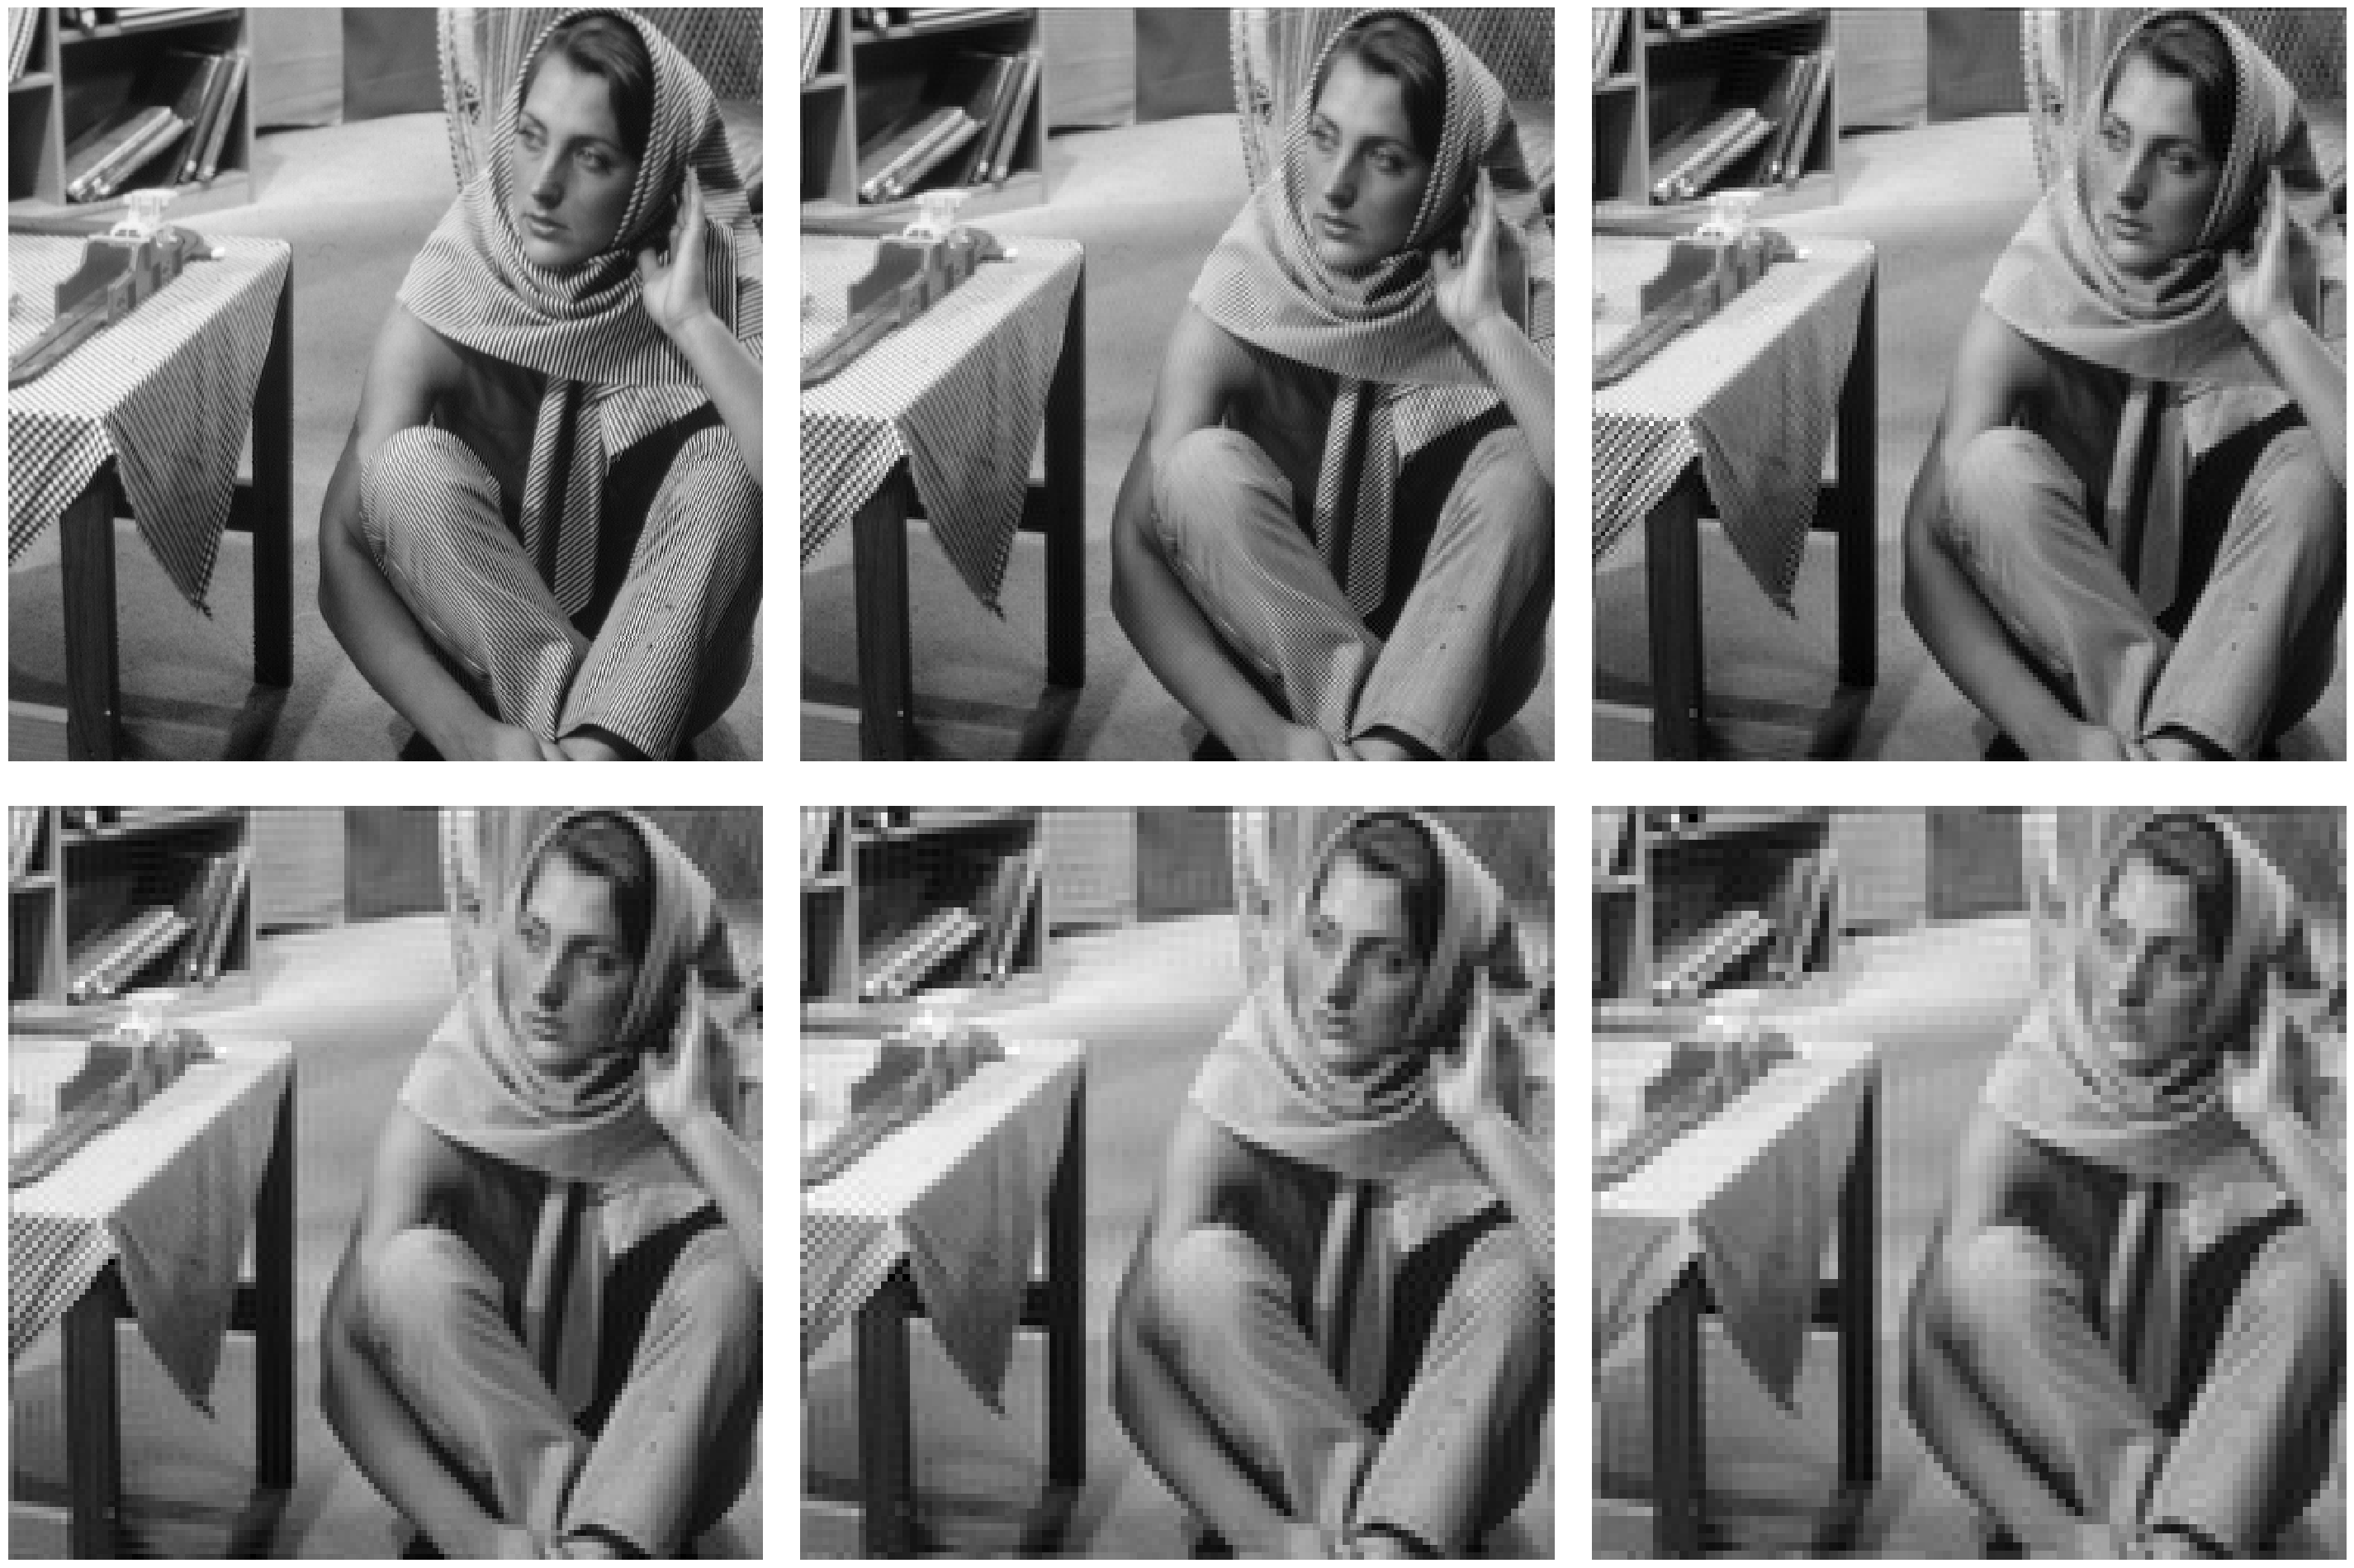

In [ ]:
barbara = open_image('barbara.png')
results = [undersample2(barbara, K) for K in [1, 2, 3, 4, 5, 6]]
display_images(results, lines=2, columns=3)

5.  Tester pour les mêmes valeurs de $K$ avec l'image $u$ de taille $128\times128$ définie par

    $$u_{m,n}=\large(-1)^{m\div32+n\div32},$$

    où $a\div b$ désigne le quotient de la division euclidienne de $a$ par $b$.

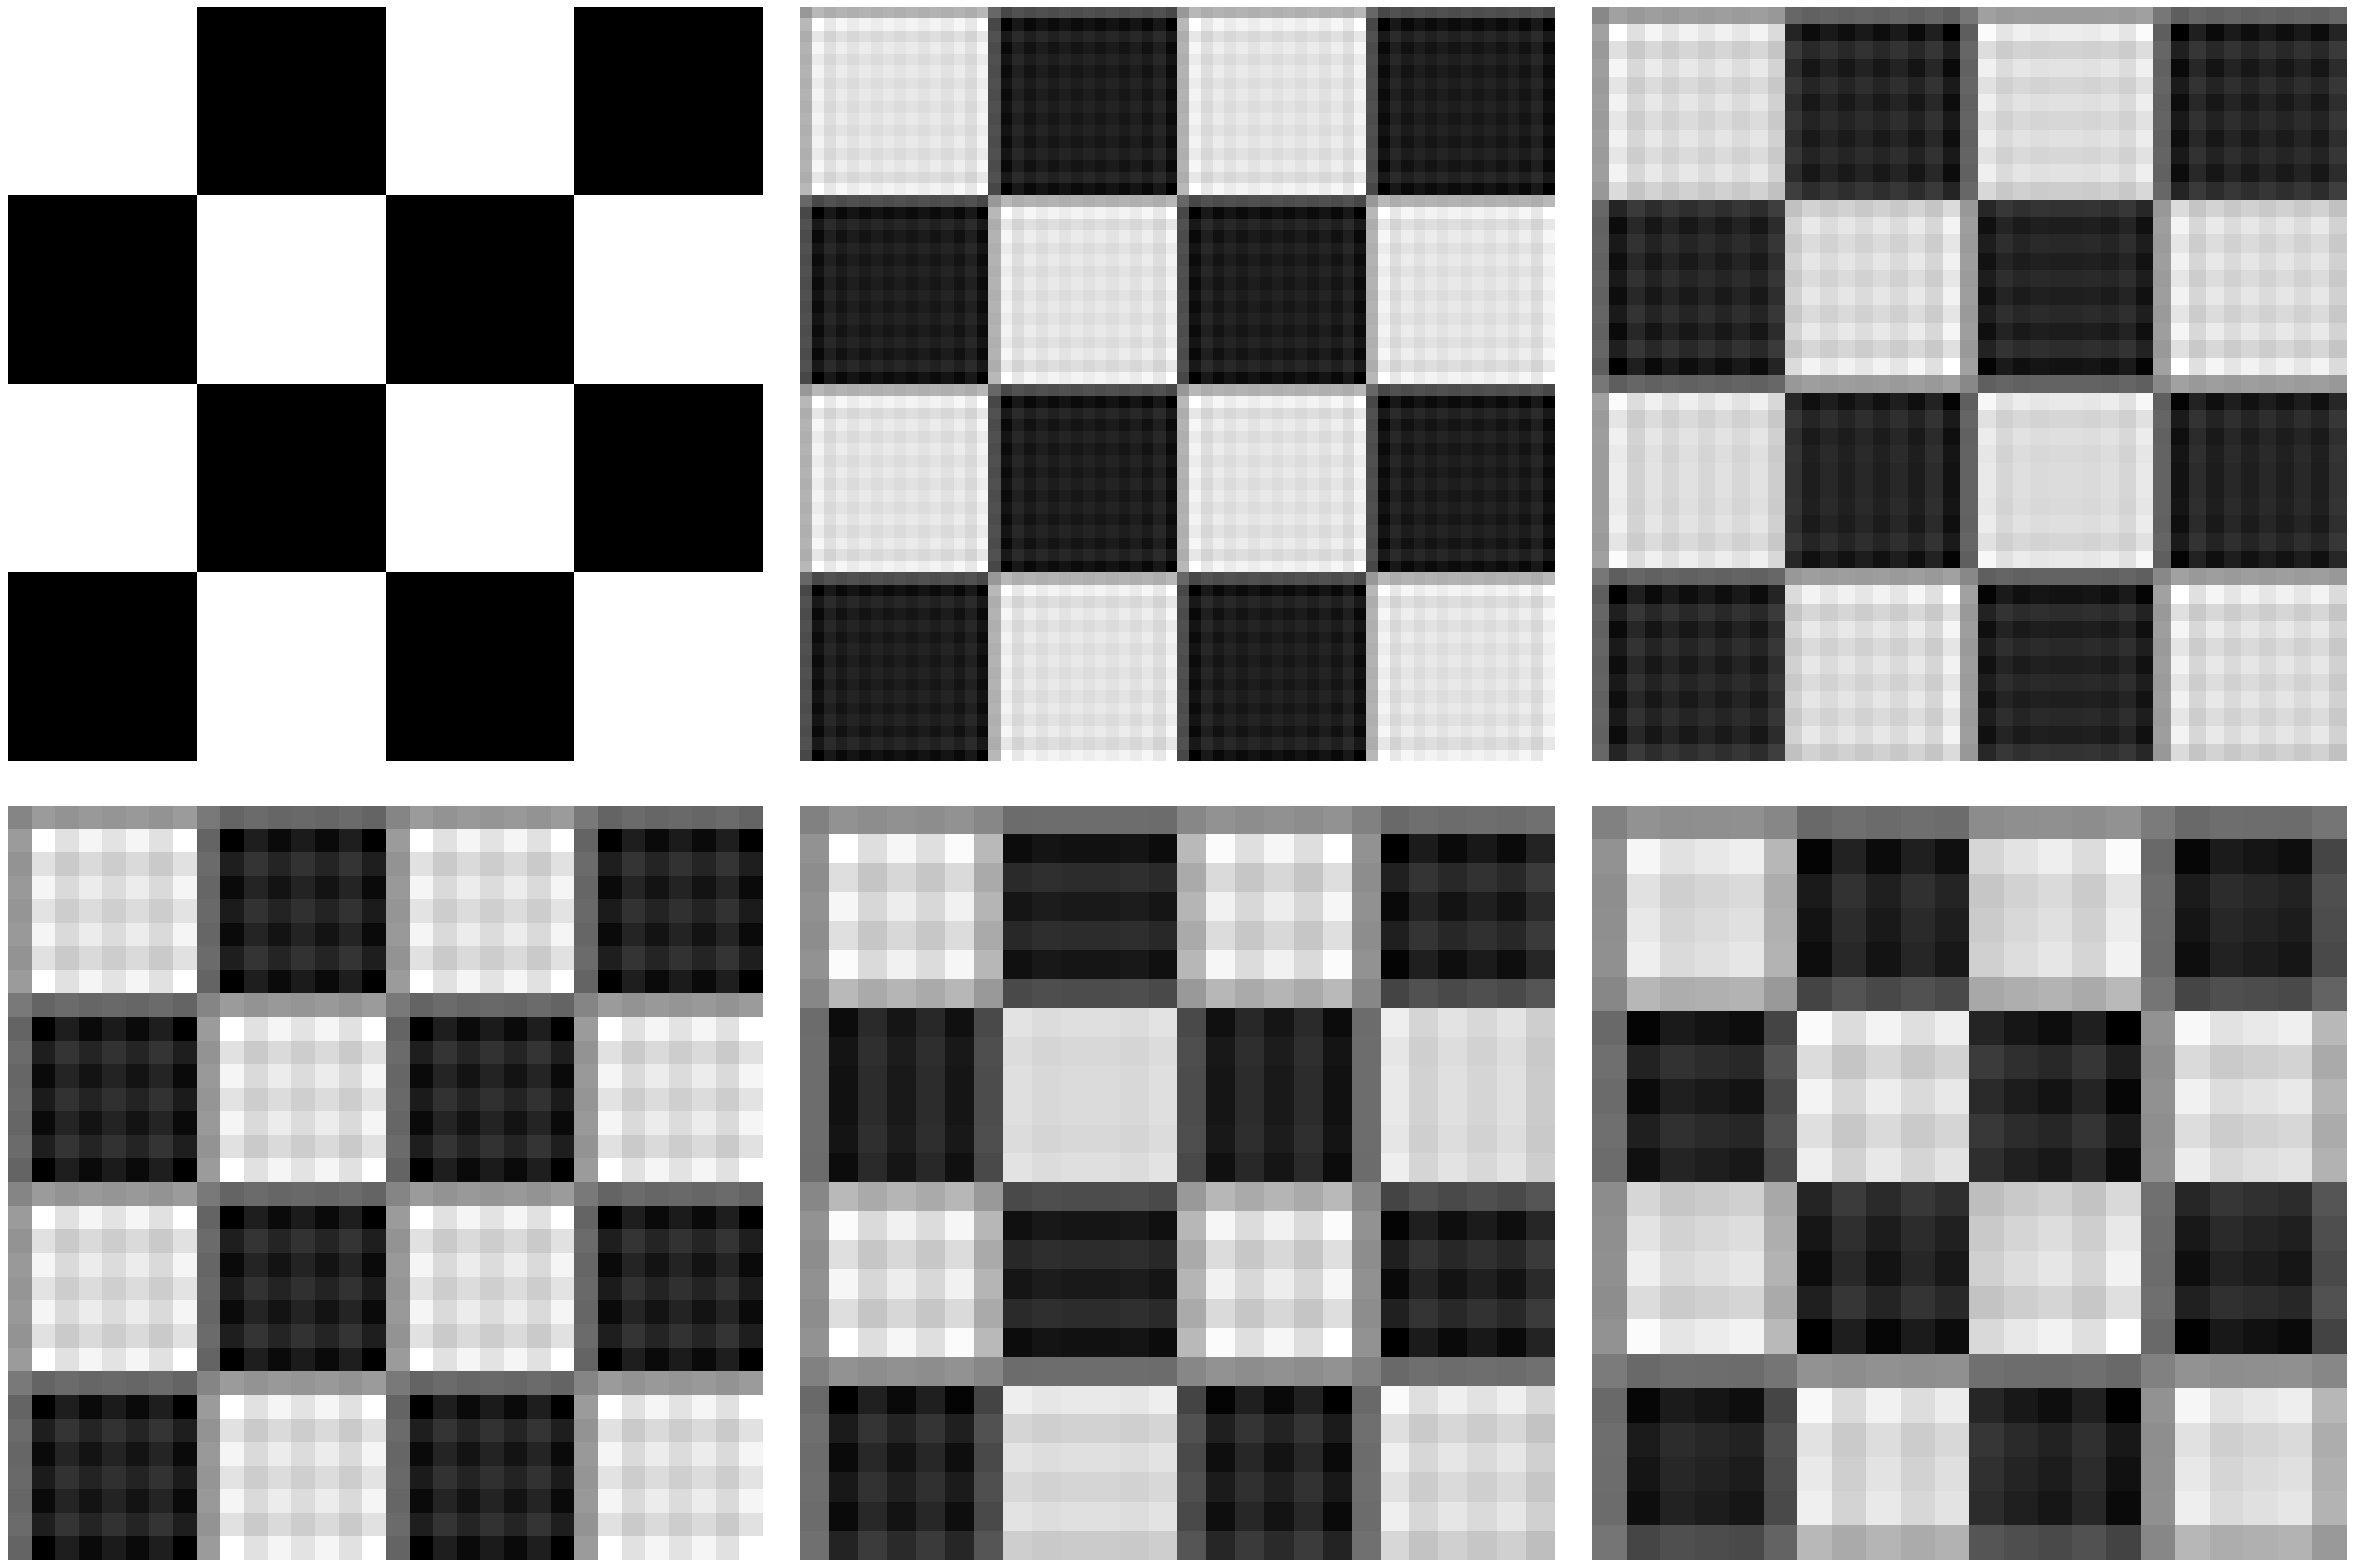

In [ ]:
N = 128
m_idx, n_idx = meshgrid(arange(N), arange(N))
u = ((-1) ** (m_idx // 32 + n_idx // 32)).astype(float)
u_display = (u + 1) * 127.5
results2 = [undersample2(u_display, K) for K in [1, 2, 3, 4, 5, 6]]
display_images(results2, lines=2, columns=3)

6.  Décrire qualitativement les résultats obtenus.

<div style="color:blue">

**Résultats exercice 1 :**

- **Sans filtre (`undersample1`)** : on observe clairement des **artefacts d'aliasing** (moirés). Des motifs basse fréquence parasites apparaissent, qui ne sont pas présents dans l'image originale. Cela est dû au repliement spectral : les hautes fréquences se « replient » sur les basses fréquences lors du sous-échantillonnage.

- **Avec filtre de Shannon (`undersample2`)** : les artefacts disparaissent complètement sur l'image `barbara.png`. L'image sous-échantillonnée semble « floue » car on a supprimé les hautes fréquences. Plus $K$ est grand, plus l'image est petite et plus l'information fine est perdue.

- **Sur l'image en damier** ($u_{m,n} = (-1)^{m\\div32+n\\div32}$) : le filtre de Shannon produit des effets de **ringing** (oscillations de Gibbs) aux bords des blocs, car le filtre passe-bas idéal a une réponse impulsionnelle de type sinc, qui oscille. Pour $K$ grand (4, 5, 6), l'image devient presque uniforme car presque toutes les fréquences sont supprimées.

</div>

## Exercice 2 – Compromis temps/fréquence

On vient de voir que le filtre de Shannon a des effets indésirables. L'alternative vue au TP1, le filtre de moyennage carré, peut causer des problèmes de flou. Nous allons à présent implémenter le filtre d'échantillonnage réalisant le compromis temps/fréquence vu en cours et TD (mesure de probabilité à support compact qui minimise la distance au filtre de Shannon).

On considère des images digitales de taille $N\times N$. Les formules qui suivent sont valables en considérant que les images sont périodisées et en se plaçant sur la fenêtre $\{-N/2,\ldots,N/2-1\}^2$ avec l'origine au centre. On introduit les deux espaces vectoriels:

$$\large BL=\left\{v\colon\forall (k,\ell)\notin U,\hat v_{k,\ell}=0\right\}$$

$$\large SL=\left\{v\colon\forall (m,n)\notin V,v_{m,n}=0\right\},$$

où $U$ et $V$ sont deux sous-domaines de $\{-N/2,\ldots,N/2-1\}^2$ respectivement en fréquence et en espace. On note respectivement $P_{BL}$ et $P_{SL}$ les projecteurs orthogonaux associés à ces deux espaces vectoriels. On rappelle que ceux-ci sont donnés par:

$$\large P_{BL}(v)=\text{ifft}(\hat v\times\mathbf 1_U)$$

$$\large P_{SL}(v)=v\times\mathbf1_V$$

1.  On prend pour $U$ la bande de fréquence de Sahnnon pour un sous-échantillonnage d'un facteur $K$, c'est à dire

    $$U=\left]-\frac N{2K},\frac N{2K}\right[^2.$$
    
    Implémenter une fonction `project_on_BL(u, K)` qui renvoie le projeté orthogonal de $u$ sur $BL$.
    
    **Indications**
    
    -   Il est possible en Python d'effectuer la multiplication par un tableau de booléens. Les valeurs `True` et `False` sont alors interprétées respectivement comme `1` et `0`. Par exemple, le code suivant va multiplier l'image `lena.png` par la fonction indicatrice de sa moitié inférieure. On pourra s'en inspirer pour effectuer des multiplications par d’autres fonctions indicatrices.

        ```python
u = open_image ("lena.png")
M, N = u.shape
m, n = meshgrid(arange(M) ,arange(N))
u[m, n] *= m > 256 # Ici : multiplication de u par une fonction indicatrice
display_image(u)
        ```

In [ ]:
def project_on_BL(u, K):
    M, N = u.shape
    U_fft = fft.fftshift(fft.fft2(u))
    m_freq = fft.fftshift(fft.fftfreq(M, 1.0/M))
    n_freq = fft.fftshift(fft.fftfreq(N, 1.0/N))
    mi, ni = meshgrid(m_freq, n_freq)
    mask = (abs(mi) < M / (2.0 * K)) & (abs(ni) < N / (2.0 * K))
    U_fft *= mask
    return real(fft.ifft2(fft.ifftshift(U_fft)))

2.  On prend pour $V$ le disque de centre $(0,0)$ et de rayon $R$:

    $$\large V=\left\{(m,n)\colon m^2+n^2\leq R^2\right\}.$$

    Implémenter une fonction `project_on_SL(u, R)` qui renvoie le projeté orthogonal de $u$ sur $SL$.

In [ ]:
def project_on_SL(u, R):
    M, N = u.shape
    m_c = arange(M) - M // 2
    n_c = arange(N) - N // 2
    mi, ni = meshgrid(m_c, n_c)
    mask = (mi**2 + ni**2 <= R**2)
    res = u.copy()
    res *= mask
    return res

3.  On note $PROBA$ l'ensemble des filtres de $SL$ qui sont des mesures de proba, c'est à dire:

    $$\large PROBA=\left\{v\in SL\colon0\leq v\leq 1\text{ et }\sum_{m,n}v_{m,n}=1\right\}.$$
    
    Cet ensemble est un convexe, et le projecteur associé peut être approché par la formule suivante:
    
    $$\large P_{PROBA}(u)=\frac{\tilde u}{\sum_{m,n}\tilde u_{m,n}},$$
    
    où $\tilde u$ est défini en replaçant les valeurs de $u$ qui sortent de l'intervalle $[0,1]$ par $0$ ou $1$:
    
    $$\large\tilde u_{m,n}=\begin{cases}0&\text{si $u_{m,n}<0$}\\1&\text{si $u_{m,n}>1$}\\u_{m,n}&\text{sinon.}\end{cases}$$
    
    Implémenter une fonction `project_on_PROBA(u)` qui renvoie $P_{PROBA}(𝑢)$.
    
    **Indication**
    
    -   Il est possible en Python de faire référence en une seule fois à tous les éléments d'un tableau vérifiant une certaine propriété. L'exemple suivant permet de mettre à zéro tous les pixels d'une image dont la valeur est inférieure à 200. On pourra s'en inspirer pour le calcul de $\tilde u$.
    
        ```python
i = open_image("lena.png")
i[i < 150] = 0 # Ici : modification de tous les pixels dont la valeur est inférieure à 150
display_image(i)
        ```

In [ ]:
def project_on_PROBA(u):
    u_tilde = u.copy()
    u_tilde[u_tilde < 0] = 0
    u_tilde[u_tilde > 1] = 1
    s = u_tilde.sum()
    if s == 0:
        return u_tilde
    return u_tilde / s

4.  On rappelle que le filtre $h_{compromis}$ de compromis temps/fréquence étudié en TD est défini comme la limite de la suite récurrente suivante:

    $$\large\begin{cases}h_0=\mathbf 1\\h_{n+1}=P_{PROBA}\circ P_{SL}\circ P_{BL}(h_n).\end{cases}$$
    
    Pour le calcul de cette limite, nous utiliserons un critère d'arrêt. Écrire une fonction `approx_filter(h0, K, R)` qui renvoie le premier filtre $h_n$ tel que $\Vert h_{n+1}-h_n\Vert_\infty<\varepsilon$ (on prendra $\varepsilon=10^{-5}$).
    
    **Indication**
    -   Lors des appels à `approx_filter`, on devra lui donner comme paramètre `h0` un tableau de la bonne taille ne contenant que des 1. On peut obtenir un tel tableau avec la fonction `ones((N, N))`.

In [ ]:
def approx_filter(h0, K, R):
    h = h0.copy()
    eps = 1e-5
    while True:
        h_new = project_on_PROBA(project_on_SL(project_on_BL(h, K), R))
        if abs(h_new - h).max() < eps:
            return h_new
        h = h_new

5.  Pour $N=32$ et $K=2$, représenter le filtre asymptotique approché pour les valeurs de $R$ suivantes: $1$, $2$, $4$, $6$, $10$.

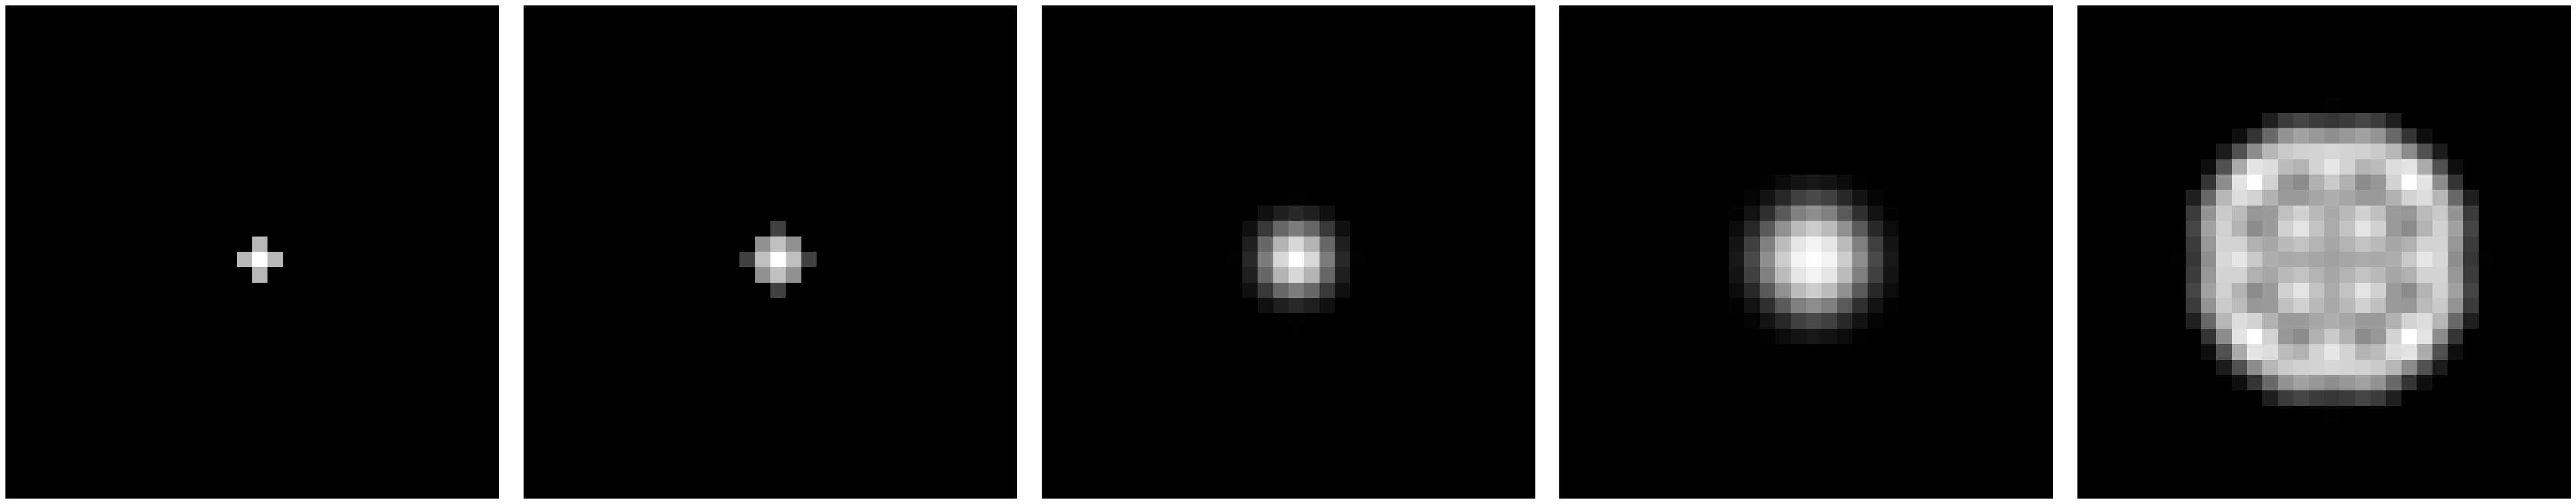

In [ ]:
N = 32
K = 2
R_values = [1, 2, 4, 6, 10]
filtres_K2 = [approx_filter(ones((N, N)), K, R) for R in R_values]
display_images(filtres_K2, lines=1, columns=5)

6.  Même question pour $K=3$.

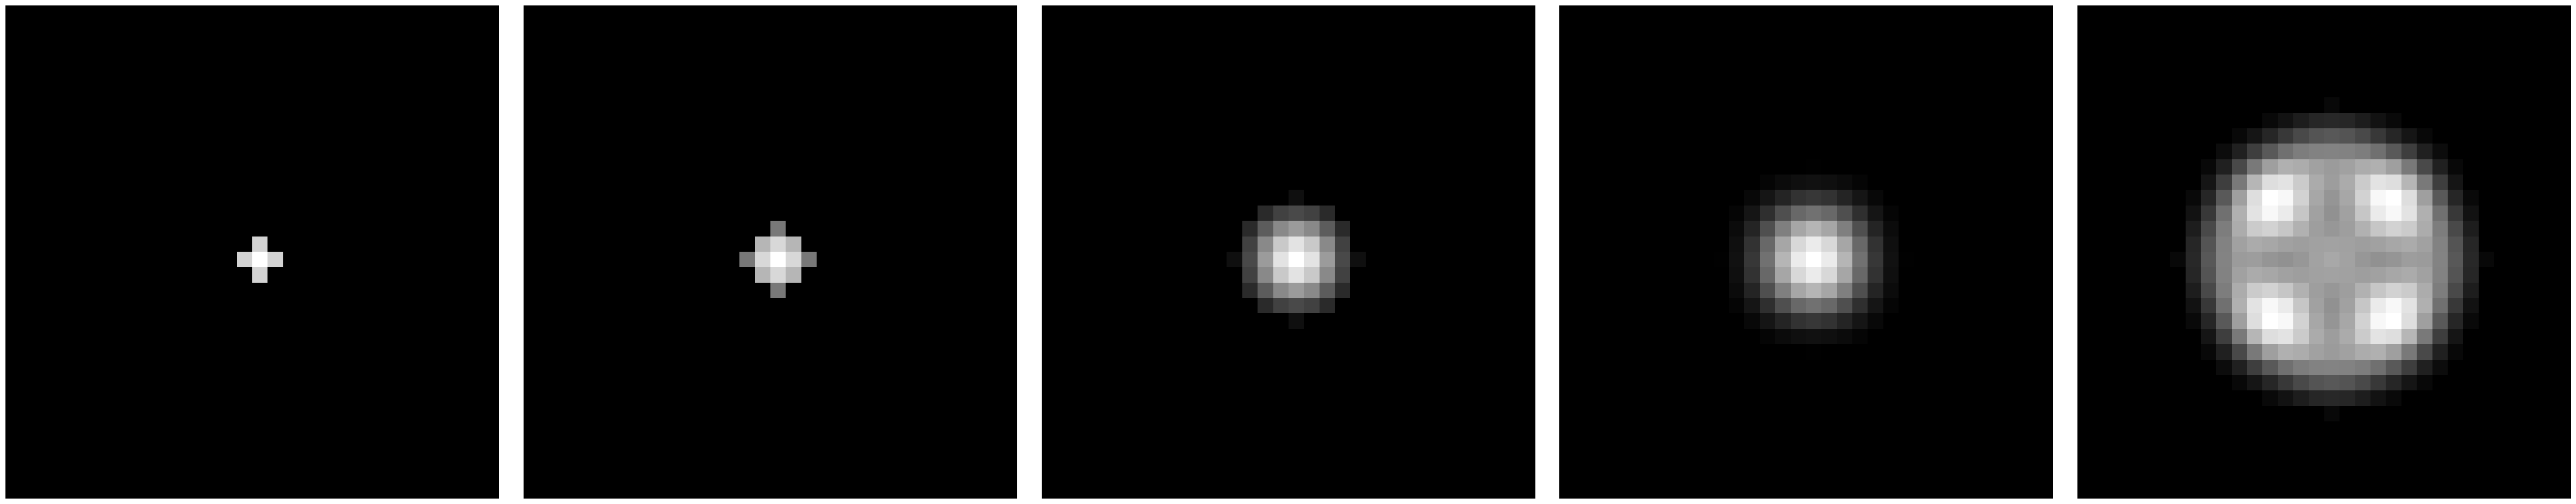

In [ ]:
N = 32
K = 3
filtres_K3 = [approx_filter(ones((N, N)), K, R) for R in R_values]
display_images(filtres_K3, lines=1, columns=5)

7.  Écrire une fonction `undersample3(u, K, R)` qui effectue l'échantillonnage de l'image $u$ d'un facteur $K$ après lui avoir appliqué le filtre asymptotique approché. La tester avec l'image `barbara.png` pour $K=2$ et avec les valeurs de $R$ suivantes: $1$, $2$, $3$, $4$. Comparer avec le résultat de `undersample2`. Quelle valeur de $R$ vous semble la mieux adaptée ?

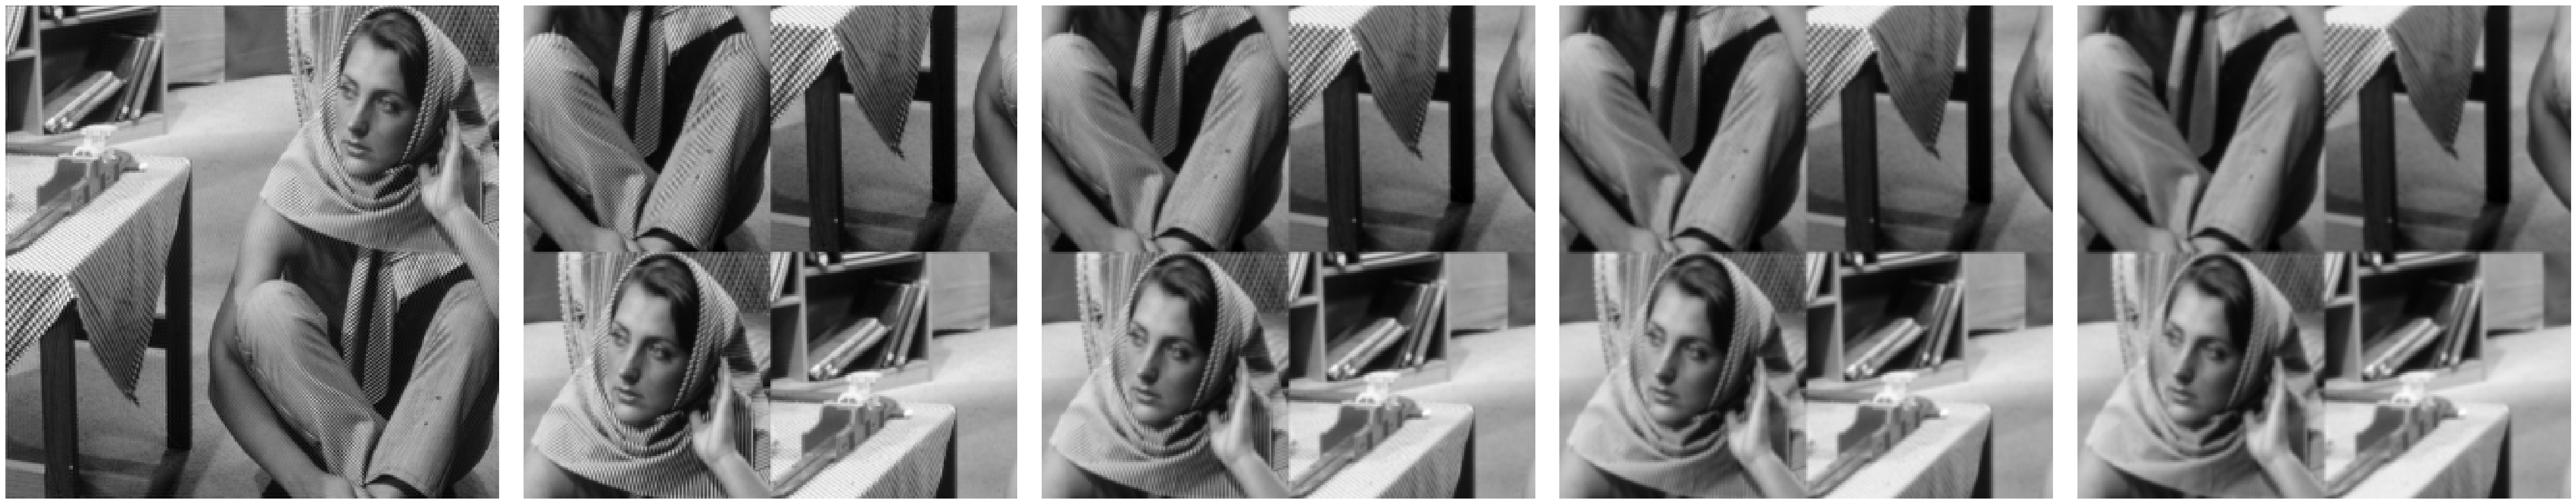

In [ ]:
def undersample3(u, K, R):
    N = u.shape[0]
    h = approx_filter(ones((N, N)), K, R)
    u_filtered = real(fft.ifft2(fft.fft2(u) * fft.fft2(h)))
    return u_filtered[::K, ::K]

barbara = open_image('barbara.png')
K = 2
res_shannon = undersample2(barbara, K)
res_compromis = [undersample3(barbara, K, R) for R in [1, 2, 3, 4]]
display_images([res_shannon] + res_compromis, lines=1, columns=5)

8.  Même question pour $K=3$ et $R\in\{2,3,4,5\}$.

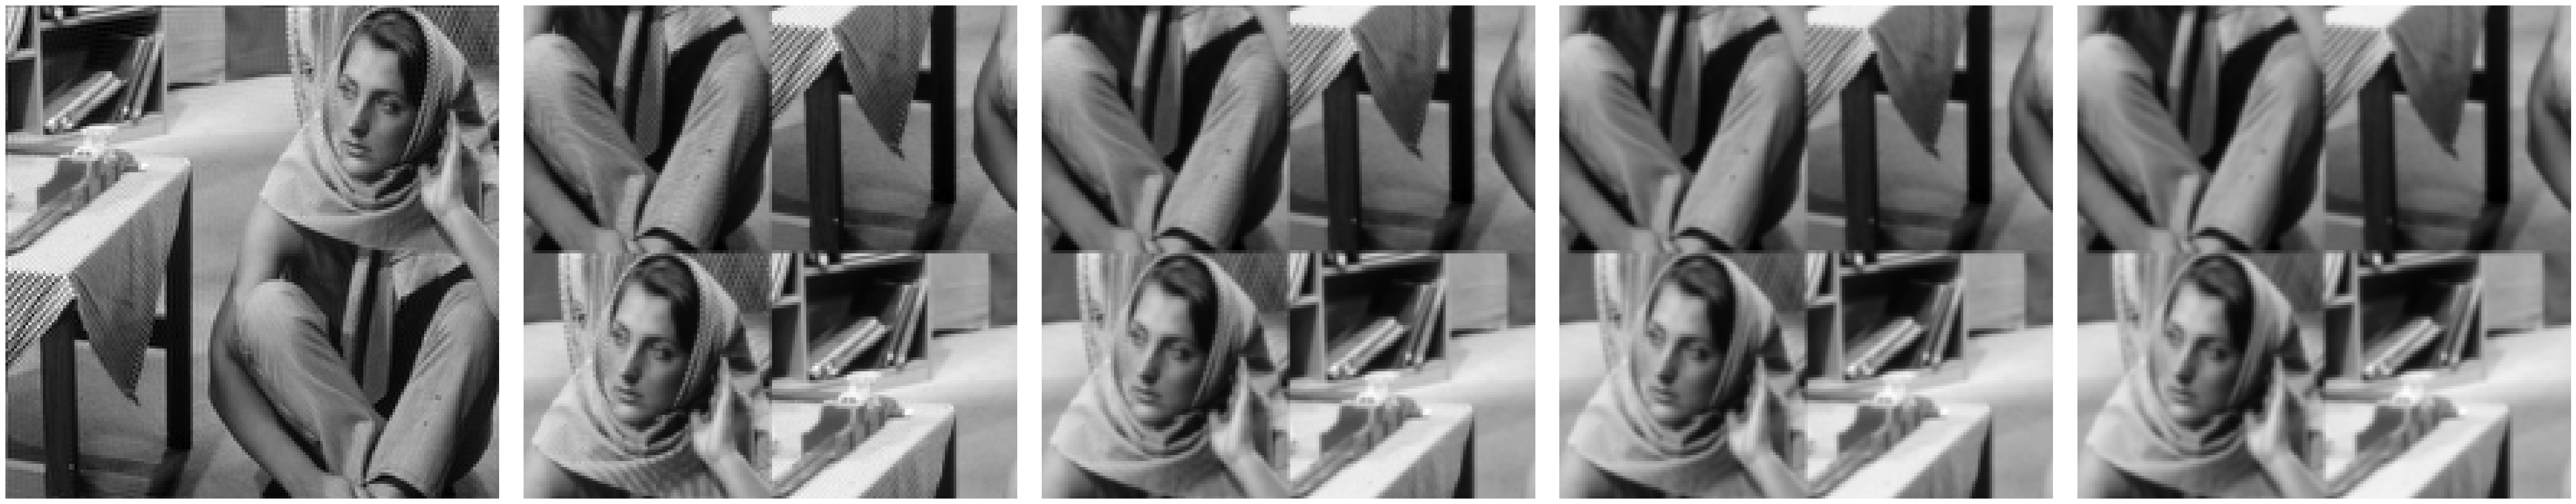

In [ ]:
K = 3
res_shannon3 = undersample2(barbara, K)
res_compromis3 = [undersample3(barbara, K, R) for R in [2, 3, 4, 5]]
display_images([res_shannon3] + res_compromis3, lines=1, columns=5)

9.  Afficher `undersample3(u, R, K)` pour $R=K\in\{2,3,4,5,6\}$ avec l'image `barbara.png`.

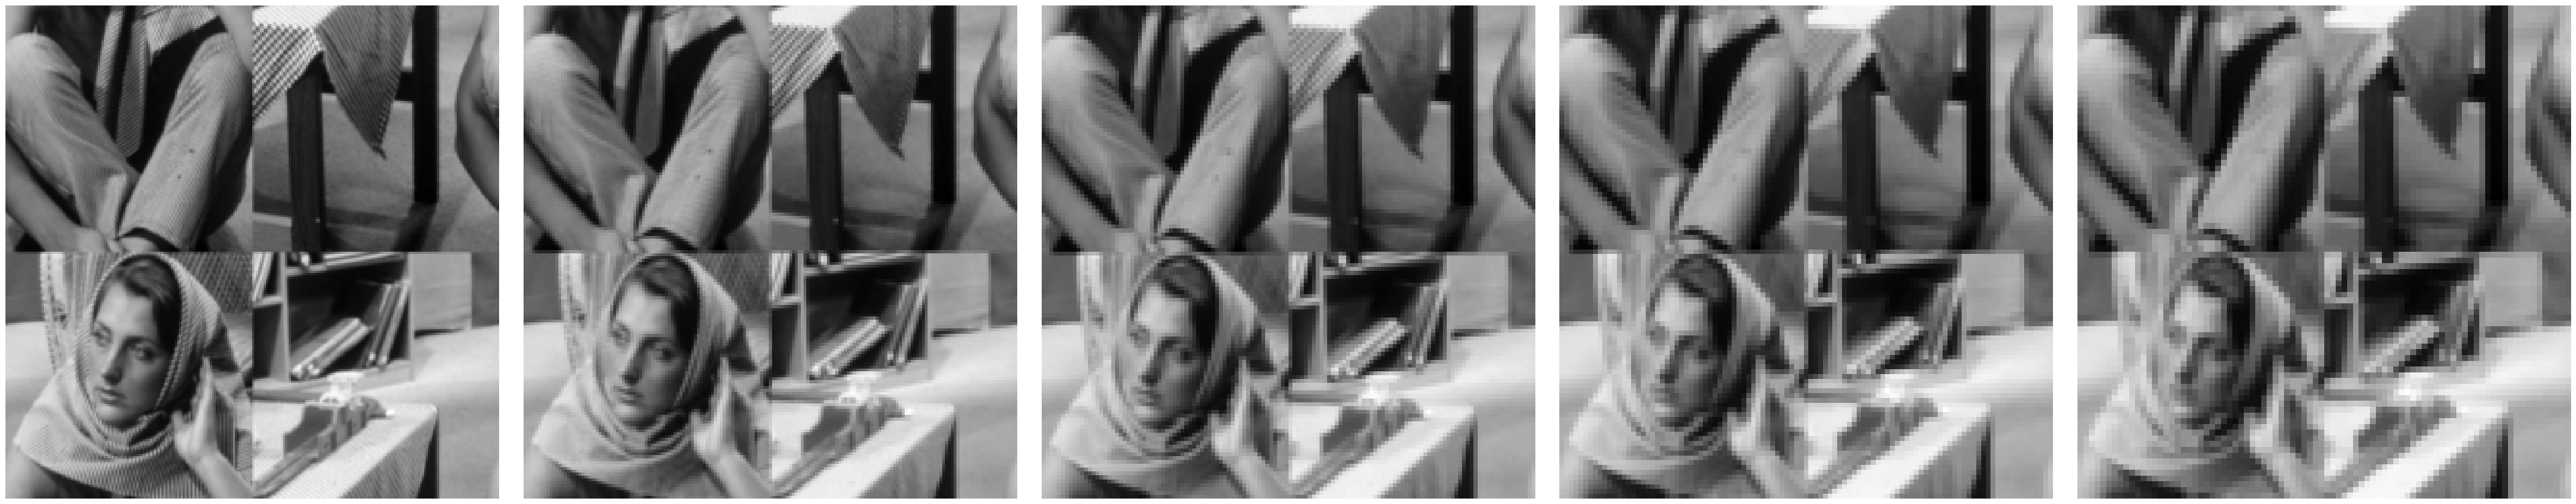

In [ ]:
barbara = open_image('barbara.png')
results_diag = [undersample3(barbara, K, K) for K in [2, 3, 4, 5, 6]]
display_images(results_diag, lines=1, columns=5)

10. Même question avec l'image $u$ utilisée dans l'exercice précédent pour $N=128$:

    $$u_{m,n}=\large(-1)^{m\div32+n\div32}.$$

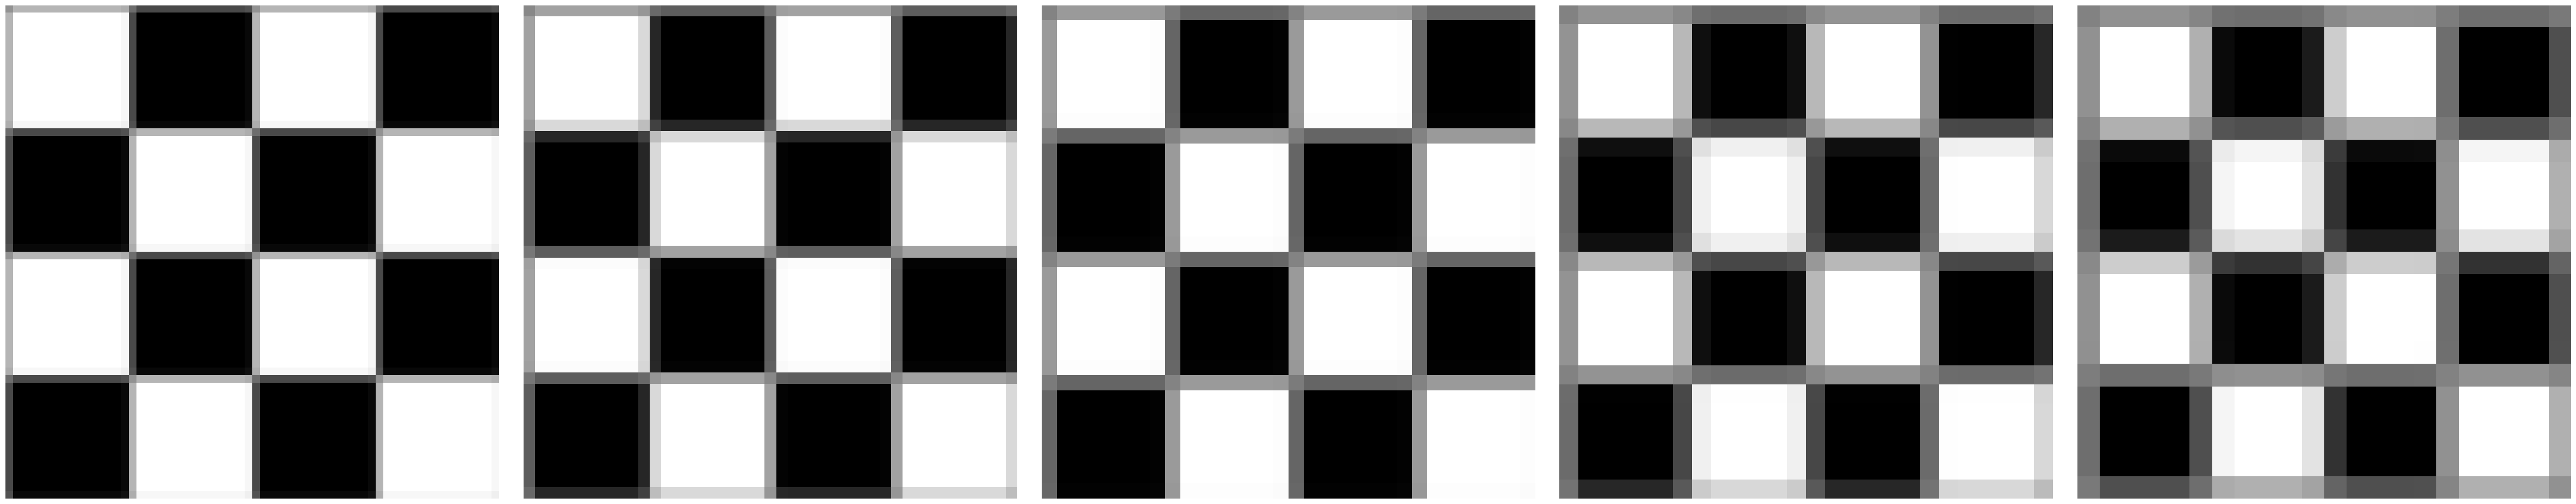

In [ ]:
N = 128
m_idx, n_idx = meshgrid(arange(N), arange(N))
u_chess = (((-1) ** (m_idx // 32 + n_idx // 32)) * 127.5 + 127.5).astype(float)
results_chess_comp = [undersample3(u_chess, K, K) for K in [2, 3, 4, 5, 6]]
display_images(results_chess_comp, lines=1, columns=5)

11. Décrire qualitativement les résultats obtenus.

<div style="color:blue">

**Résultats exercice 2 :**

- Le **filtre compromis** (filtre asymptotique) est une mesure de probabilité à support spatial compact (disque de rayon $R$) qui approxime au mieux le filtre de Shannon dans $BL$. Il possède donc une bonne localisation à la fois en espace et en fréquence.

- Pour **$R$ petit** : le filtre est très localisé spatialement (support spatial réduit), ce qui produit peu de ringing mais un filtrage fréquentiel moins précis. L'image résultante peut présenter davantage d'aliasing résiduel.

- Pour **$R$ grand** : le filtre se rapproche du filtre de Shannon, ce qui diminue l'aliasing mais augmente les oscillations de Gibbs (ringing) autour des contours.

- Sur `barbara.png`, les valeurs $R = K$ semblent offrir un bon compromis : les textures sont bien conservées et les artefacts sont minimaux.

- Sur l'image damier, le filtre compromis produit moins d'oscillations de Gibbs que le filtre de Shannon pur, tout en supprimant correctement les fréquences trop élevées.

</div>

# Applications

## Exercice 3 – Zoom numérique

On s'intéresse à présent au problème inverse du sous-échantillonnage : à partir d'une image de taille $N\times N$, comment recomposer une image de taille $KN\times KN$ en complétant les données manquantes?

1.  Préparer les images de travail de taille $32\times 32$ suivantes :
    -   $\large u^1$ définie comme la restriction de `lena.png` à $\{250,\ldots,281\}\times\{309,\ldots,340\}$;
    -   $\large u^2_{m,n}=(-1)^{m\div8+n\div8}$
    -   $\large u^3_{m,n}=m$
    -   $\large u^4_{m,n}=\cos\left(\dfrac{\pi(m+n)}8\right)$.

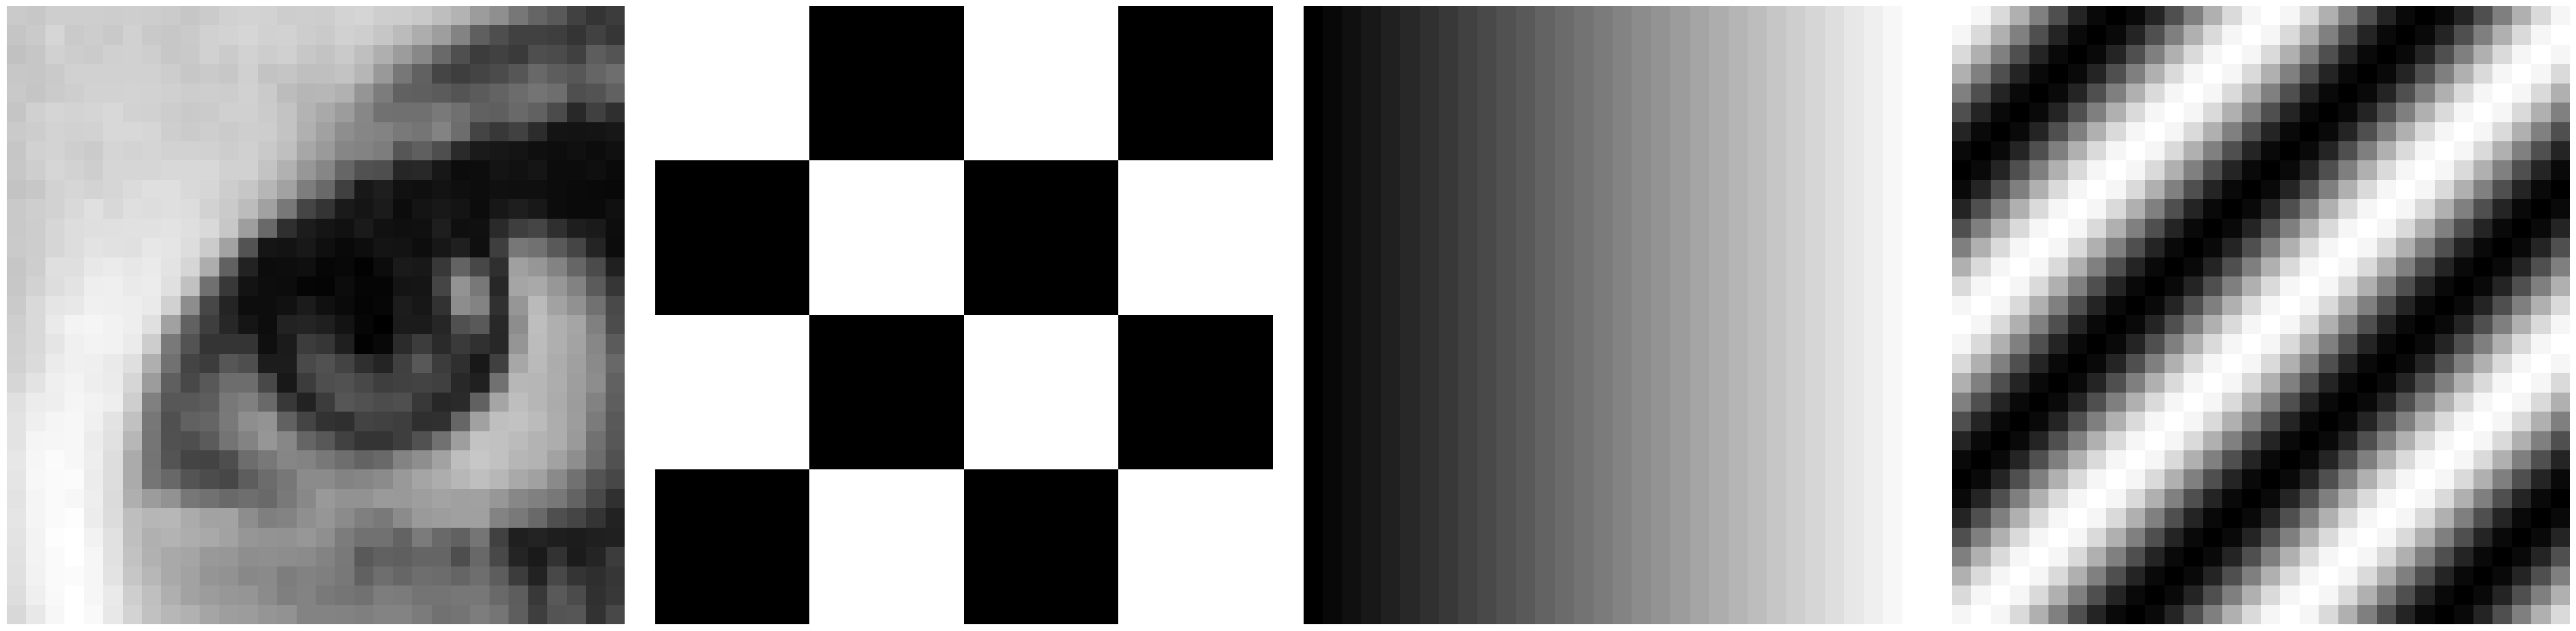

In [ ]:
lena = open_image('lena.png')
# u1 : restriction de lena à {250,...,281}x{309,...,340}
u1 = lena[250:282, 309:341].copy()

# u2
N32 = 32
m32, n32 = meshgrid(arange(N32), arange(N32))
u2 = (((-1) ** (m32 // 8 + n32 // 8)) * 127.5 + 127.5).astype(float)

# u3
u3 = m32.astype(float)

# u4
u4 = cos(pi * (m32 + n32) / 8.0) * 127.5 + 127.5

display_images([u1, u2, u3, u4], lines=1, columns=4)

2.  Une première idée pour implémenter un zoom numérique consiste à utiliser une approximation par plus proche voisin. Définir une fonction `oversample1(u, K)` qui renvoie l'image $v$ dont les dimensions sont celles de $u$ multipliées par $K$, et telle que

    $$v_{m,n}=u_{m\div K,n\div K}.$$

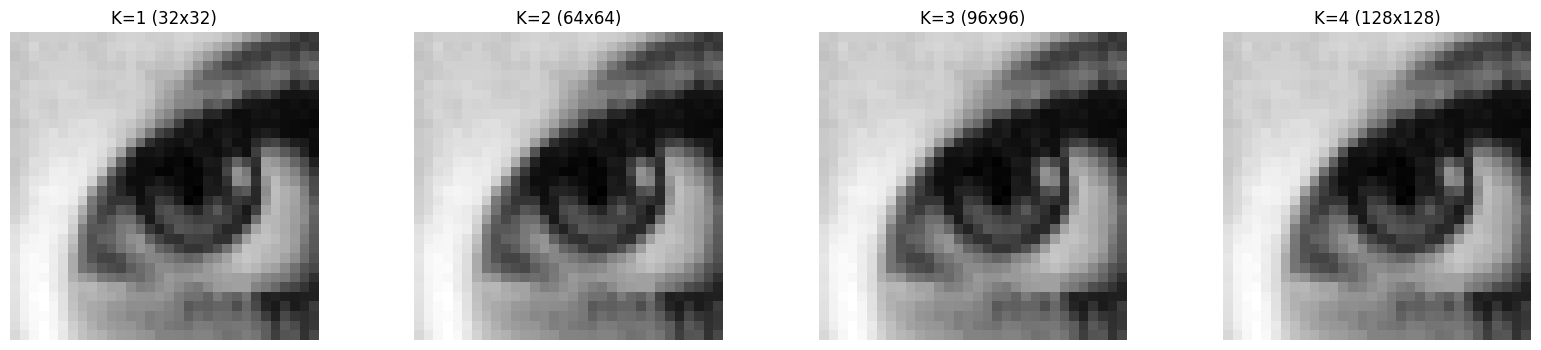

In [ ]:
def oversample1(u, K):
    M, N = u.shape
    m_big, n_big = meshgrid(arange(K * M), arange(K * N), indexing='ij')
    return u[m_big // K, n_big // K]


'''res = []
for img in [u1, u2, u3, u4]:
    for K in range(1, 5):
        res.append(oversample1(img, K))

display_images(res, lines=4, columns=4)'''
import matplotlib.pyplot as plt

images = [oversample1(u1, K) for K in range(1, 5)]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, K in zip(axes, range(1, 5)):
    img = oversample1(u1, K)
    ax.imshow(img, cmap='gray', interpolation='nearest')
    ax.set_title(f'K={K} ({img.shape[0]}x{img.shape[1]})')
    ax.axis('off')
    # Forcer la taille des axes proportionnelle à l'image
    ax.set_aspect('equal')

plt.show()

3.  Une deuxième idée consiste à voir la transformée de Fourier de l'image (avant zoom) comme la restriction de la transformée de Fourier d'une image plus grande (autrement dit, qui aurait subi un filtrage de Shannon).

    Définir une fonction `oversample2(u, K)` qui, pour une image $u$ de taille $N\times N$, renvoie l'image $v$ de taille $KN\times KN$ telle que, sur une période centrée sur l'origine:
    
    $$\large\hat v_{k,\ell}=\begin{cases}\hat u_{k,\ell}&\text{si $(k,\ell)\in\left\{-\frac N2+1,\frac N2-1\right\}$}\\0&\text{sinon.}\end{cases}$$
    
    Tester `oversample2` avec les images de travail pour $K=1,2,3,4$.

16


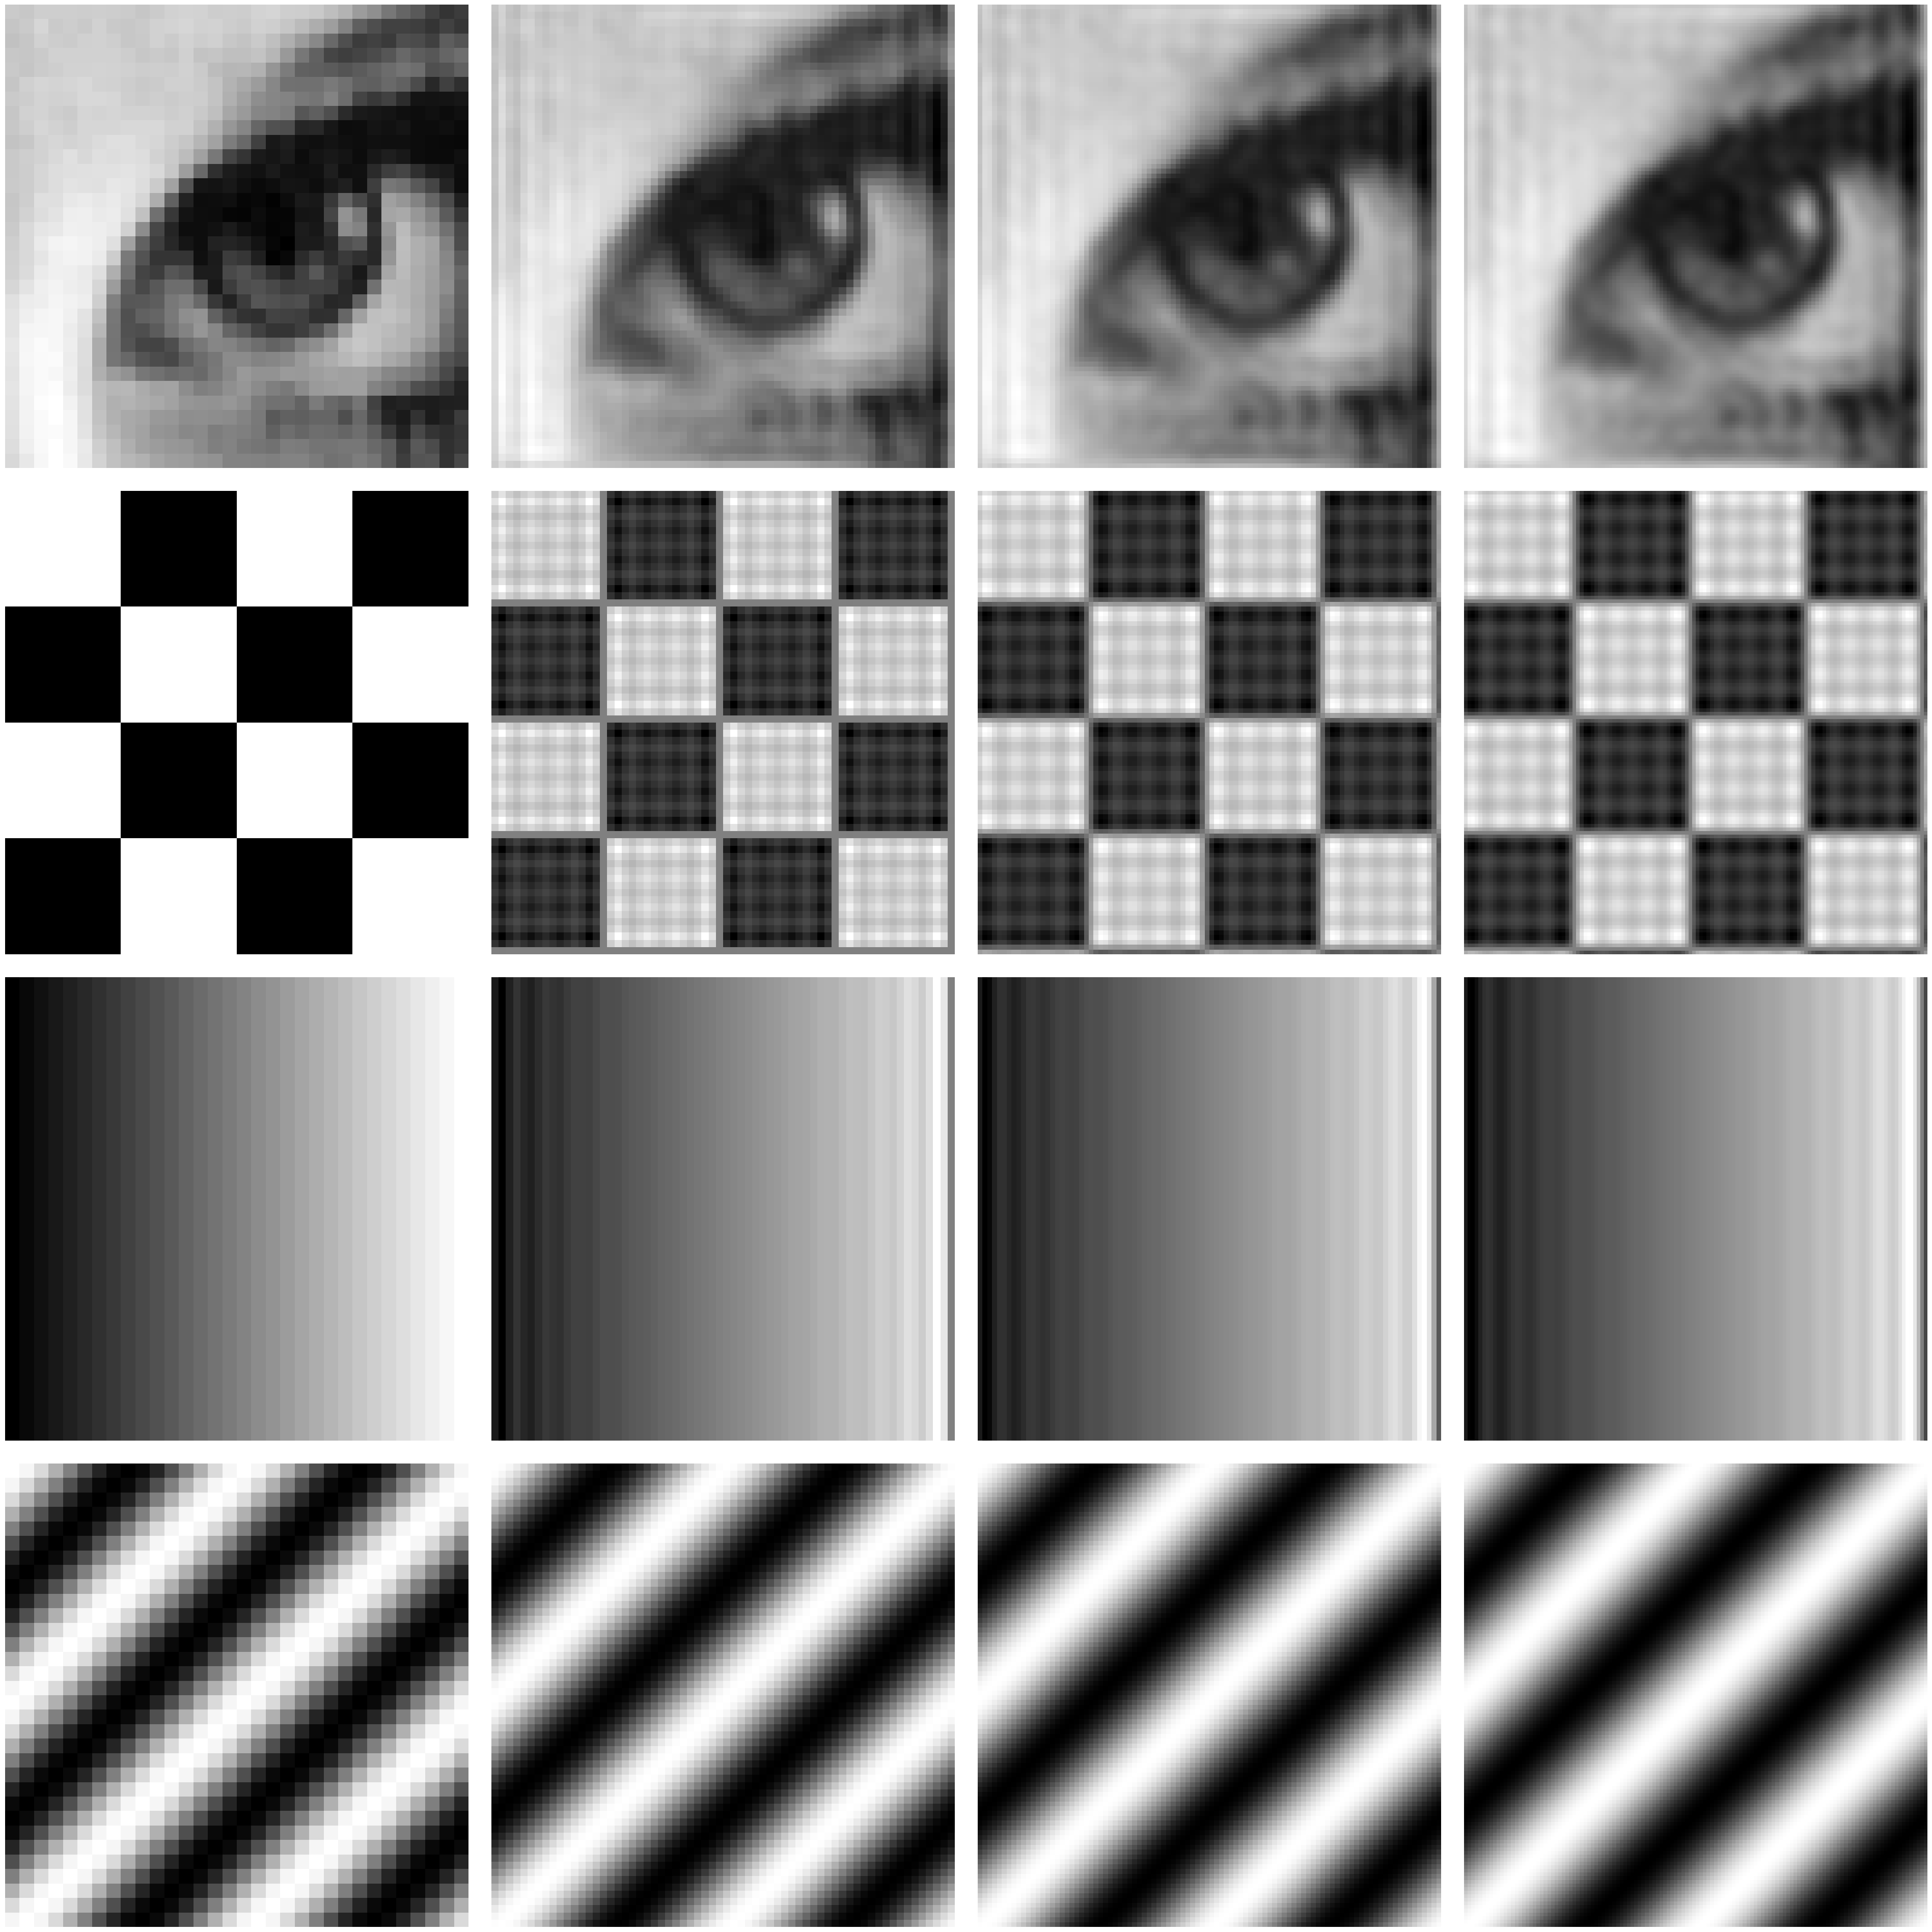

In [ ]:
def oversample2(u, K):
    M, N = u.shape
    U_fft = fft.fftshift(fft.fft2(u))
    KM, KN = K * M, K * N
    V_fft = zeros((KM, KN), dtype=complex)
    dm = (KM - M) // 2
    dn = (KN - N) // 2
    V_fft[dm:dm+M, dn:dn+N] = U_fft
    v = real(fft.ifft2(fft.ifftshift(V_fft))) * K**2
    return v

res = []
for img in ([u1, u2, u3, u4]):
    for K in range(1,5):
        res.append(oversample2(img, K))

print(len(res))
display_images(res, lines=4, columns=4)


#display_images(res, lines=1, columns=4)

4.  Enfin une troisième idée consiste à faire un compromis entre localisation fréquentielle et spatiale.

    Définir une fonction `oversample3(u, K)` qui renvoie l'image obtenue après avoir appliqué le filtre asymptotique approché de l'exercice 2 à l'approximation par plus proche voisin définie à la question 2).
    
    Tester `oversample3` avec les images de travail pour $K=1,2,3,4$.

16


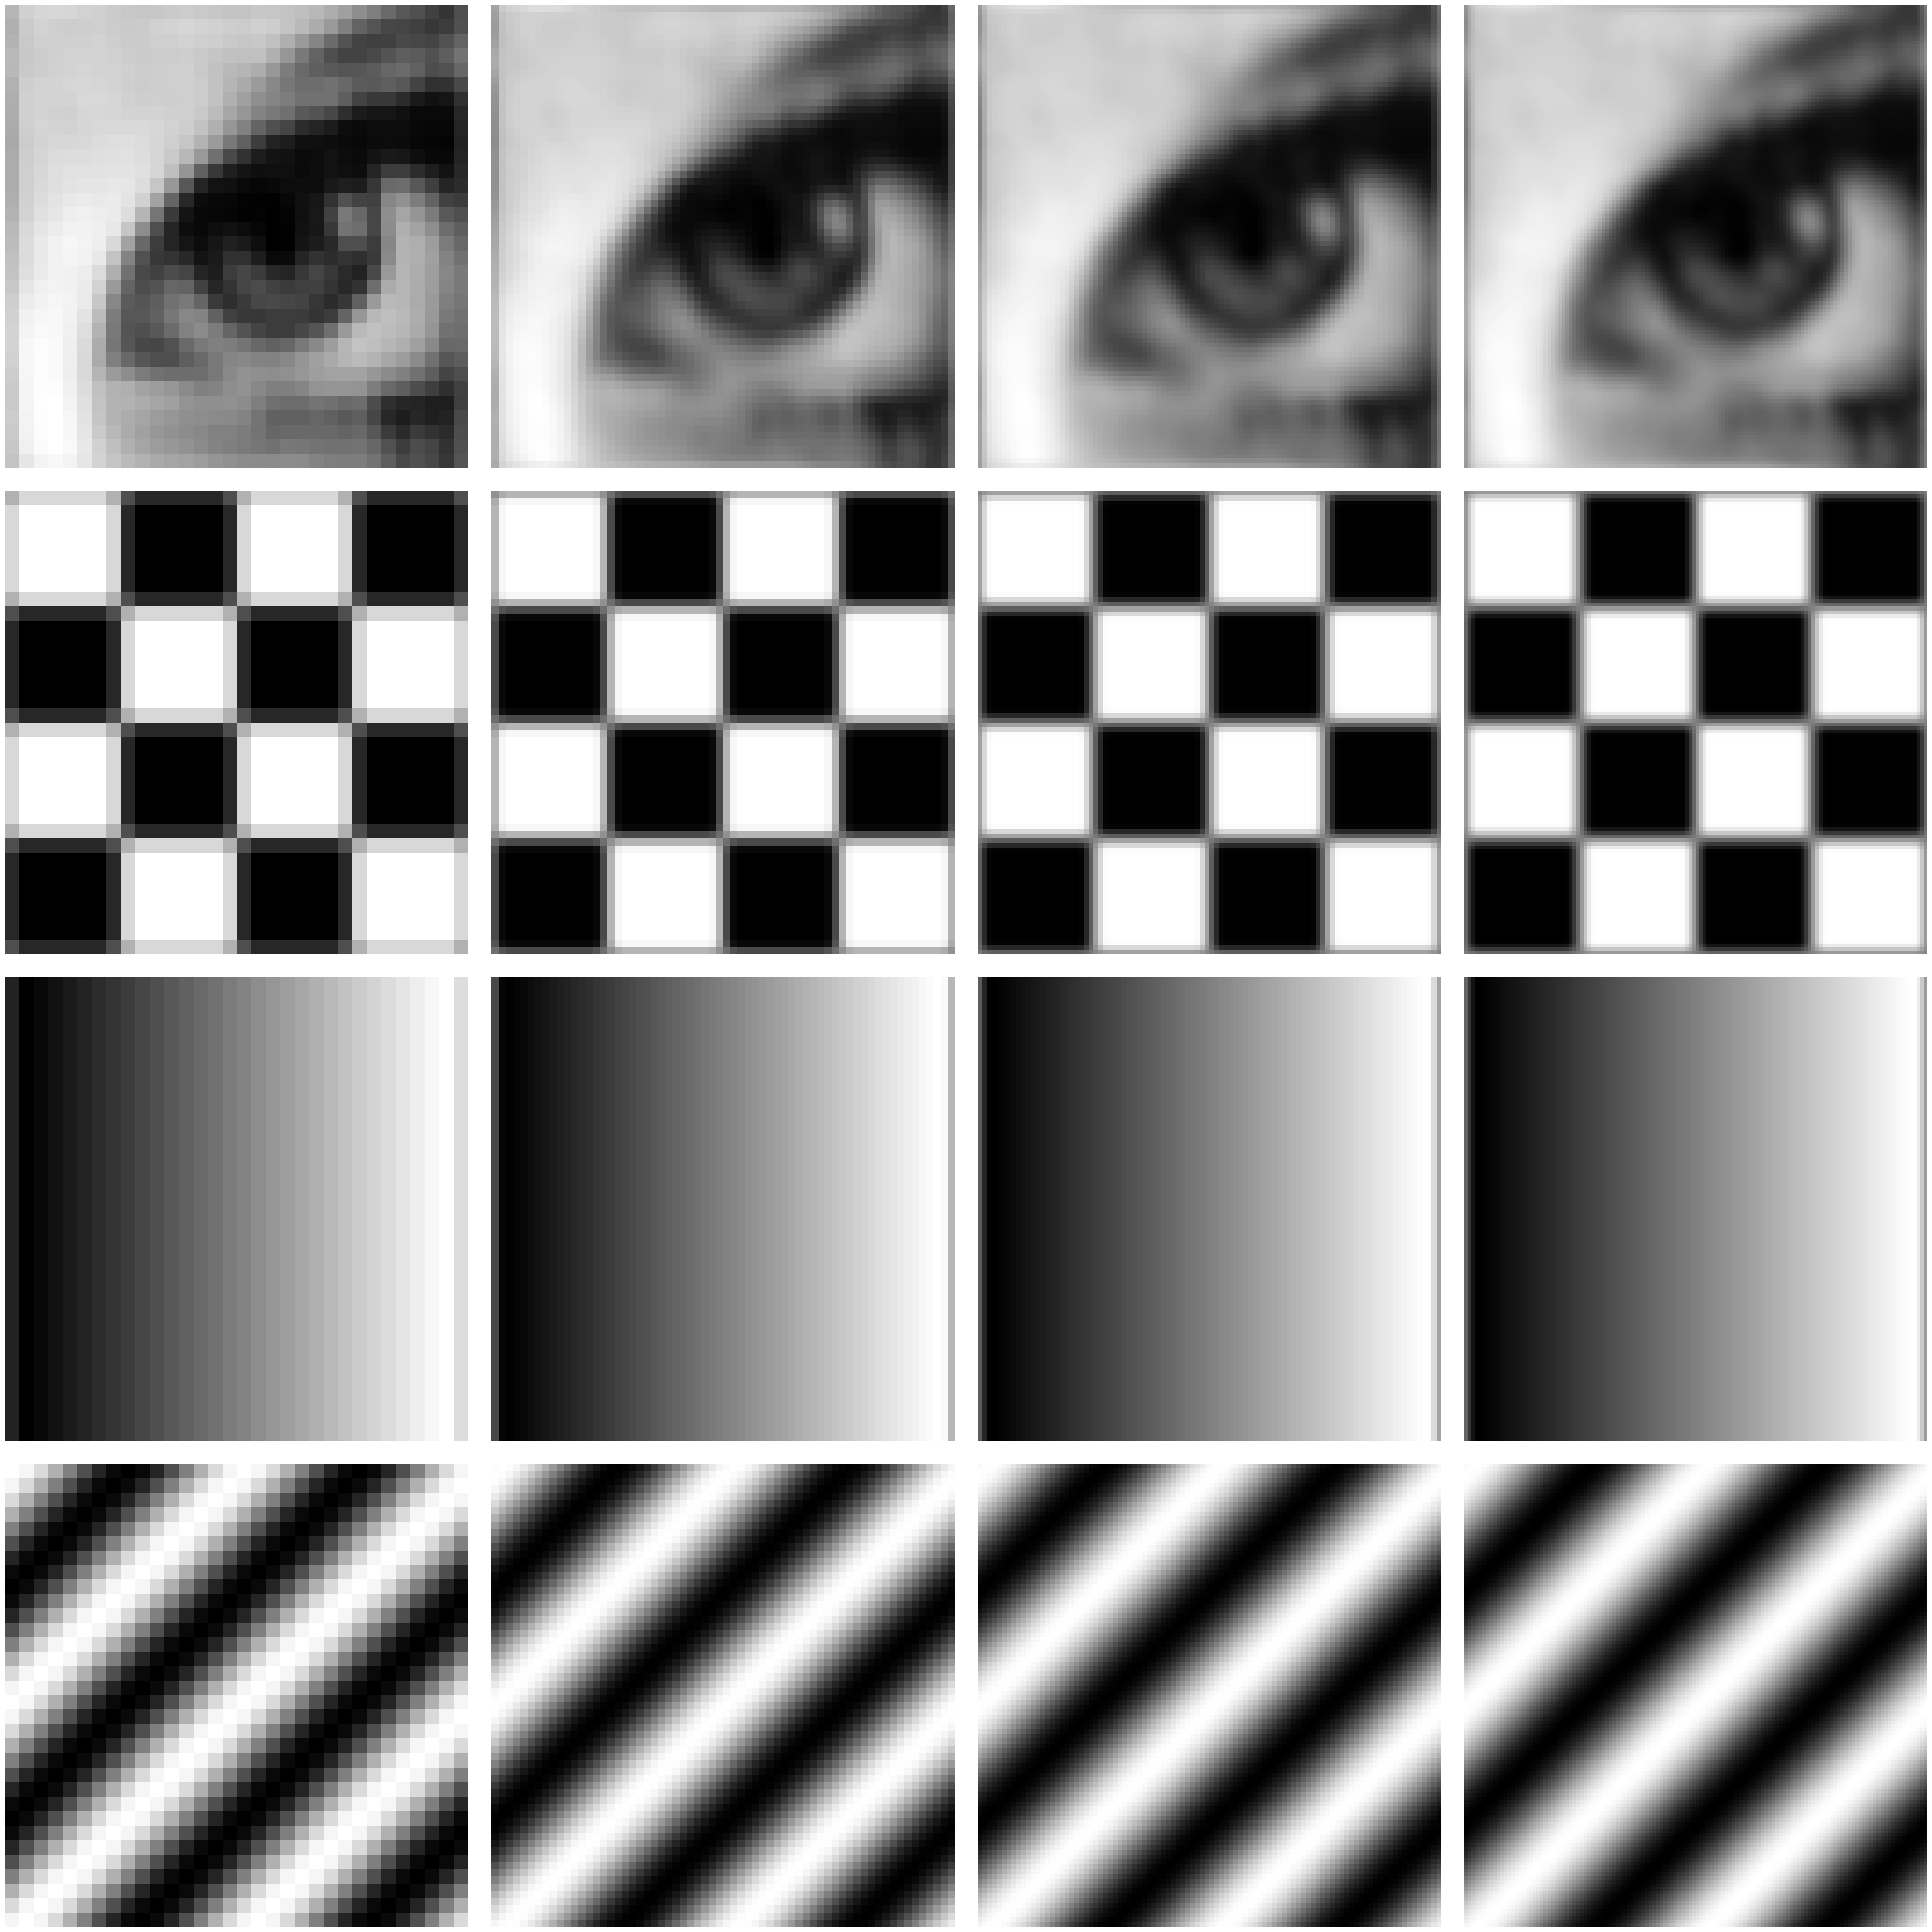

In [ ]:
def oversample0(u, K):
    v = oversample1(u, K) 
    N_big = v.shape[0]
    h = approx_filter(ones((N_big, N_big)), K, K) 
    v_filtered = real(fft.ifft2(fft.fft2(v) * fft.fft2(h)))
    return v_filtered

def oversample3(u, K):
    # 1. On commence par le zoom grossier (Plus proche voisin)
    v = oversample1(u, K)
    N_big_m, N_big_n = v.shape
    
    # 2. Récupération du filtre de ton exercice 2 (on suppose qu'il renvoie un filtre spatial)
    # Si approx_filter prend les dimensions de l'image, on lui passe (N_big_m, N_big_n)
    h = approx_filter(ones((N_big_m, N_big_n)), K, K)
    
    # 3. CRUCIAL : Normalisation du filtre pour éviter que l'image ne devienne blanche ou noire
    if h.sum() != 0:
        h = h / h.sum()
        
    # 4. Passage dans le domaine fréquentiel
    # On applique fftshift sur le filtre spatial pour ramener son centre mathématique à l'origine (0,0)
    # Cela supprime le déphasage qui dupliquait l'image en 4 !
    V_fft = fft.fft2(v)
    H_fft = fft.fft2(fft.fftshift(h)) 
    
    # 5. Multiplication (Convolution rapide) et retour dans l'espace
    v_filtered = real(fft.ifft2(V_fft * H_fft))
    
    return v_filtered

res = []
for img in ([u1, u2, u3, u4]):
    for K in range(1,5):
        res.append(oversample3(img, K))

print(len(res))
display_images(res, lines=4, columns=4)

# Tomographie

En imagerie médicale, on veut étudier la densité $f$ d'un organe. Pour cela, on place une source de rayons X devant la partie du corps à étudier et un écran derrière. Sur l'écran, on mesure la quantité de rayons X qui a été absorbée.

Intuitivement, on peut dire qu'on mesure la "projection" de l'organe sur l'écran. On note $H$ l'écran (assimilé à $\mathbb R^2$) et, pour $s\in H$ on note $\Delta(s)$ la droite perpendiculaire à $H$ et passant par $s$. Mathématiquement, en tout point $s$ de l'écran, on mesure:

$$\large\mathcal R_Hf(s)=\int_{x\in\Delta(s)}f(x)\,dx$$

![Transformée de Radon dans $R^3$](http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/radon.png)

La transformation obtenue est appelée la *transformée de Radon* de $f$. Comme les calculs impliqués sont assez lourds, nous allons nous limiter au cas de la dimension 2. Dans ces conditions, $H$ est une droite qu'on va paramétrer par un angle $\theta$. On a alors la formule:

$$\large\forall\theta\in\left[0,\pi\right[,\forall s\in\mathbb R\colon\mathcal R_\theta f(s):=\int_{-\infty}^{+\infty}f(s\cos\theta-t\sin\theta,s\sin\theta+t\cos\theta)\,dt.$$

![Transformée de Radon dans $R^3$](http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/tomography.png)


## Exercice 4 – Transformée de Radon

Nous allons commencer par implémenter une transformée de Radon pour les images discrètes. Pour cela, on considère une image numérique $u$ de taille $N\times N$ et on va remplacer l'intégrale dans la formule précédente par une somme de Riemann de l'approximation par plus proche voisin de $u$:

$$\large\forall\theta\in\left[0,\pi\right[,\forall s\in\left[-\frac N2,\frac N2\right]\colon\mathcal Ru(\theta,s):=\frac1N\sum_{t=-N/2}^{N/2}u_{\text{round}\left(s\cos\theta-t\sin\theta+\frac N2\right),\text{round}\left(s\sin\theta+t\cos\theta+\frac N2\right)}$$

1.  La formule précédente n'est valable que si le support de $v$ est inclus dans le disque de rayon $\frac N2$ au centre de l'image. Pour garantir que cette condition est vérifiée, définir une fonction `enlarge(u)` qui prend en paramètre une image de taille $N\times N$ et qui renvoie l'image de taille $2N\times 2N$ obtenue en entourant $u$ d'une bande noire de largeur $\frac N2$.

In [ ]:
def enlarge(u):
    N = u.shape[0]
    big = zeros((2 * N, 2 * N))
    big[N//2:N//2+N, N//2:N//2+N] = u
    return big

2.  Définir une fonction `radon(u, M)` qui applique d'abord `enlarge` à $u$ puis qui renvoie sa transformée de Radon discrète $v$ définie pour un échantillonnage de l'angle $\theta$ sur $M$ valeurs. Plus précisément, on veut que $v$ soit l'image de taille $M\times N$ vérifiant :

    $$\large\forall (m,n)\in\{0,\ldots,M-1\}\times\{0,\ldots,N-1\}\colon v_{m,n}=\mathcal Ru\left(\frac{m\pi}M,n-\frac N2\right).$$
    
    On appelle l'image obtenue un *sinogramme*.
    
    **Indications** 
    
    Le calcul de $\mathcal Ru$ ayant une complexité élevée, il est recommandé d'utiliser les fonctionnalités de vectorisation de `meshgrid`. On pourra remarquer que le calcul de $v_{m,n}$ se résume à une somme du type $\displaystyle\sum_{t=-N/2}^{N/2}u_{k,\ell}$, où $k$ et $\ell$ sont des indices qui dépendent de $m$, $n$ et $t$. Il y a deux problèmes techniques à résoudre lors de l'implémentation vectorisée de cette somme :
    
    -   les indices $k$ et $\ell$ sont définis dans les formules précédentes à l'aide de la fonction `round`, qui existe en Python. Toutefois, celle-ci ne renvoie pas des entiers, mais des nombres flottants. Il faut donc convertir son résultat en nombres entiers avec `astype(int)`;
    
    -   certains indices $k$ ou $\ell$ vont se retrouver à l'extérieur du fenêtrage $\{0,\ldots,N-1\}$. Ici, il ne faut pas périodiser l'image comme on le fait d’habitude. Les termes correspondants de la somme doivent être remplacés par des zéros. Une manière de s’en assurer est de remplacer ces indices $(k,\ell)$ par des coordonnées de pixels situés sur le bord de l'image (qui sont donc noirs, puisqu'on aura préalablement utilisé `enlarge`).
    
    Voici un squelette possible de l'algorithme, il ne reste plus qu'à compléter les pointillés.
    
    ```python
    def radon(u, M):
        u = enlarge(u)
        N = u.shape[0]
        v = zeros((M, N))
        m, n = meshgrid(arange(M), arange(N))
        for t in range(-N / 2, N / 2 + 1):
            theta = ...
            s = ...
            k = np.round(...).astype(int) # calcul des indices k en fonction de m, n et t
            l = np.round(...).astype(int) # calcul des indices l en fonction de m, n et t
            k[k < 0] = 0                  # ajustement des indices situés trop haut
            k[k >= N] = N - 1             # ajustement des indices situés trop bas
            l[l < 0] = 0                  # ajustement des indices situés trop à gauche
            l[l >= N] = N - 1             # ajustement des indices situés trop à droite
            v[m, n] += u[k, l]
        return v / N
    ```

In [ ]:
def radon(u, M):
    u = enlarge(u)
    N = u.shape[0]
    v = zeros((M, N))
    m_idx, n_idx = meshgrid(arange(M), arange(N))
    for t in range(-N // 2, N // 2 + 1):
        theta = m_idx * pi / M
        s = n_idx - N / 2.0
        k = around(s * cos(theta) - t * sin(theta) + N / 2.0).astype(int)
        l = around(s * sin(theta) + t * cos(theta) + N / 2.0).astype(int)
        k[k < 0] = 0
        k[k >= N] = N - 1
        l[l < 0] = 0
        l[l >= N] = N - 1
        v[m_idx, n_idx] += u[k, l]
    return v / N

3.  Tester votre algorithme avec les images de taille $64\times64$ suivantes (on pourra prendre par exemple $M=180$):

    $\large u^1_{m,n}=\mathbf1_{(m-32)^2+(n-32)^2<500}$
    
    $\large u^2_{m,n}=\mathbf1_{\left\vert n-32\right\vert<2}$
    
    $\large u^3_{m,n}=\mathbf1_{\left\vert 64-m-n\right\vert<2}$
    
    $\large u^4_{m,n}=\mathbf1_{\left\vert 32-m-n\right\vert<2}$
    
    $\large u^5_{m,n}=\mathbf1_{\left\vert 64-m\sqrt3-n\right\vert<2}+\mathbf1_{\left\vert 50-n\right\vert<2}+\mathbf1_{\left\vert m-n\sqrt3\right\vert<2}$


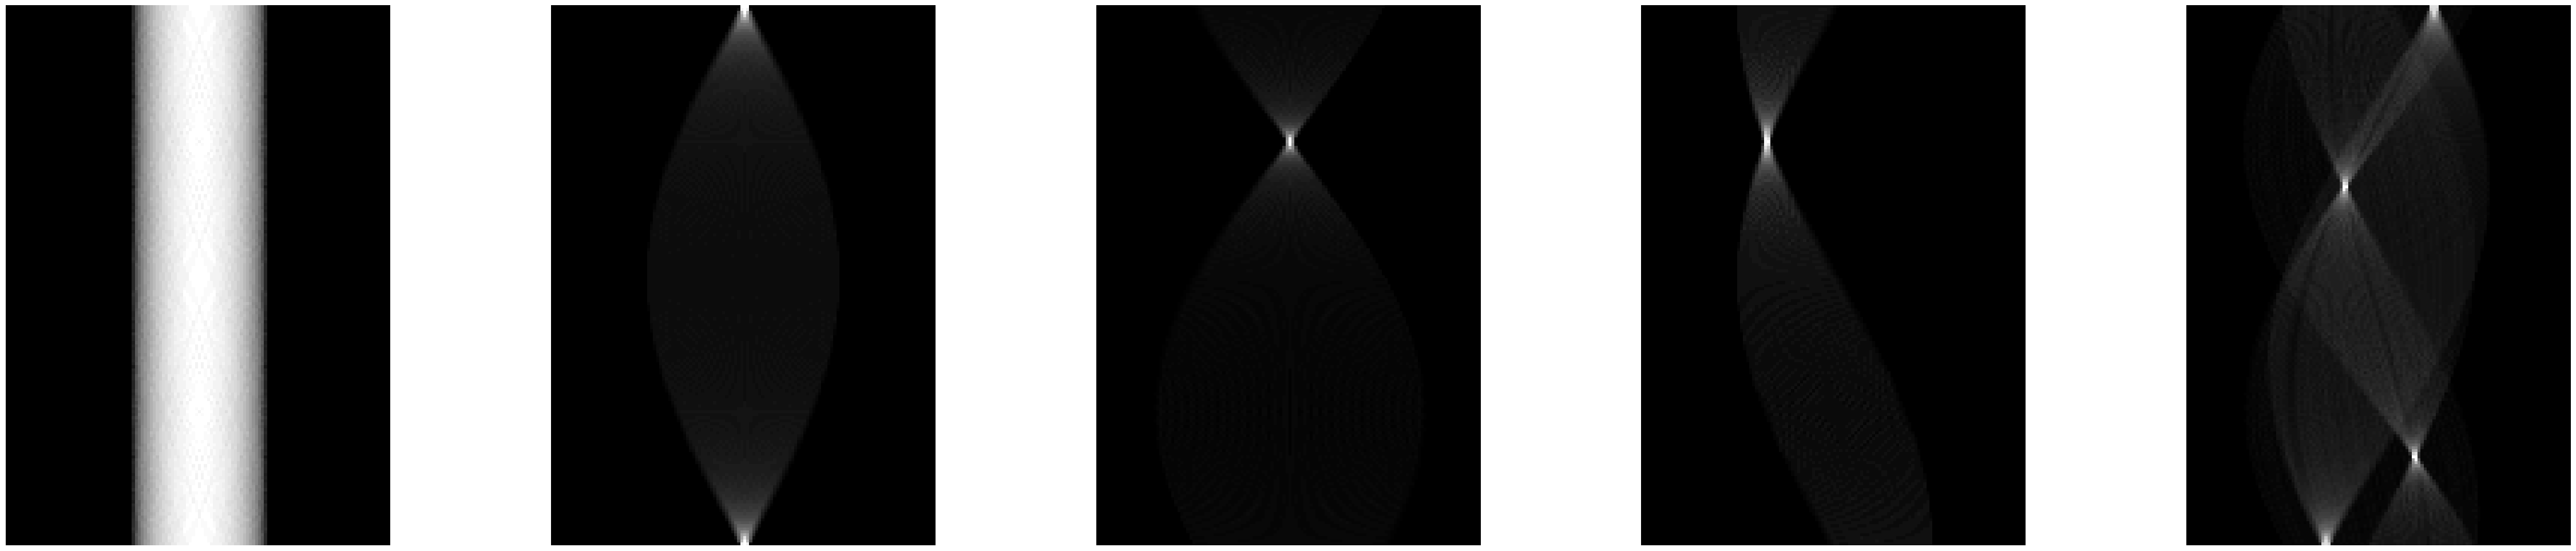

In [ ]:
SZ = 64
M_radon = 180
mr, nr = meshgrid(arange(SZ), arange(SZ))

u_r1 = ((mr - 32)**2 + (nr - 32)**2 < 500).astype(float) * 255
u_r2 = (abs(nr - 32) < 2).astype(float) * 255
u_r3 = (abs(64 - mr - nr) < 2).astype(float) * 255
u_r4 = (abs(32 - mr - nr) < 2).astype(float) * 255
u_r5 = ((abs(64 - mr * sqrt(3) - nr) < 2) + (abs(50 - nr) < 2) + (abs(mr - nr * sqrt(3)) < 2)).astype(float) * 127

sinograms = [radon(u, M_radon) for u in [u_r1, u_r2, u_r3, u_r4, u_r5]]
display_images([u_r1, u_r2, u_r3, u_r4, u_r5], lines=1, columns=5)
display_images(sinograms, lines=1, columns=5)

4.  Décrire qualitativement les résultats obtenus.

<div style="color:blue">

- **$u^1$ (disque)** : le sinogramme montre des courbes sinusoïdales larges et symétriques, reflétant le fait que la projection d'un disque est maximale quand la droite de projection passe par son centre, pour tout angle.

- **$u^2$ (ligne verticale)** : la projection est nulle sauf pour $\\theta \\approx 0$ (direction perpendiculaire à la ligne), où elle donne un pic très marqué. Le sinogramme présente une bande brillante verticale à la position angulaire correspondant à la normale de la ligne.

- **$u^3$ et $u^4$ (lignes diagonales)** : similaires à $u^2$ mais avec un décalage angulaire correspondant à l'angle de la droite. Les pics apparaissent à l'angle $\\theta$ pour lequel la direction de projection est perpendiculaire à la ligne.

- **$u^5$ (triangle équilatéral)** : le sinogramme est la superposition des trois sinogrammes des segments composants. On voit trois familles de pics correspondant aux trois orientations des côtés du triangle.

En résumé, **une droite dans l'image correspond à un point (sinusoïde) dans le sinogramme**, et la transformée de Radon est un changement de représentation : espace $(x,y)$ → espace $(\\theta, s)$.

</div>

## Exercice 5 – Transformée de Radon inverse

On s'intéresse à présent au problème de la reconstruction d'une image connaissant sa transformée de Radon. 

1.  On rappelle que

    $$\large\forall\theta\in\left[0,\pi\right[,\forall s\in\mathbb R\colon\mathcal R_\theta f(s)=\int_{-\infty}^{+\infty}f(s\cos\theta-t\sin\theta,s\sin\theta+t\cos\theta)\,dt.$$

    Dans cette formule, on peut constater que $R_\theta f(s)$ s'écrit comme l'intégrale par rapport à $t$ de $f\circ R_\theta(s,t)$, où $R_\theta$ désigne la rotation d'angle $\theta$:
    
    $$\large R_\theta f(s)=\int_{-\infty}^{+\infty}f\circ R_\theta(s,t)\,dt.$$
    
    À l'aide du changement de variables $(x,y)=R_\theta(s,t)$ (il faut prendre $dx\,dy= ds\,dt$) et en admettant que $\mathcal R_\theta f\in L^1$, montrer que
    
    $$\large\forall\lambda\in\mathbb R\colon \hat f(\lambda\cos\theta,\lambda\sin\theta)=\widehat{\mathcal R_\theta f}(\lambda).$$

<div style="color:blue">

**Preuve (théorème de la tranche de Fourier) :**

On part de la définition de la transformée de Radon :
$$
\mathcal{R}_{\theta} f(s) = \int_{-\infty}^{+\infty} f(s\cos\theta - t\sin\theta, \, s\sin\theta + t\cos\theta) \, dt
$$

La transformée de Fourier unidimensionnelle de $\mathcal{R}_{\theta} f$ en $\lambda$ est :
$$
\widehat{\mathcal{R}_{\theta} f}(\lambda) = \int_{-\infty}^{+\infty} \mathcal{R}_{\theta} f(s) \, e^{-2i\pi\lambda s} \, ds = \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} f(s\cos\theta - t\sin\theta, \, s\sin\theta + t\cos\theta) \, e^{-2i\pi\lambda s} \, dt \, ds
$$

On effectue le changement de variables $(x,y) = R_{\theta}(s,t)$, c'est-à-dire :
$x = s\cos\theta - t\sin\theta$ et $y = s\sin\theta + t\cos\theta$.

Comme $R_{\theta}$ est une rotation, son Jacobien est $1$, donc $dx \, dy = ds \, dt$. 
De plus, on a la relation inverse pour $s$ : $s = x\cos\theta + y\sin\theta$. 

On obtient alors :
$$
\widehat{\mathcal{R}_{\theta} f}(\lambda) = \int_{\mathbb{R}^2} f(x,y) \, e^{-2i\pi\lambda (x\cos\theta + y\sin\theta)} \, dx \, dy = \hat{f}(\lambda\cos\theta, \, \lambda\sin\theta)
$$

On a donc bien :
$$
\hat{f}(\lambda\cos\theta, \, \lambda\sin\theta) = \widehat{\mathcal{R}_{\theta} f}(\lambda) \quad \square
$$

</div>

2.  En effectuant cette fois le changement de variable $(\xi,\nu)=(\lambda\cos\theta,\lambda\sin\theta)$ pour $(\lambda,\theta)\in\mathbb R\times[0,\pi]$ dans la formule de reconstruction de Fourier de $f$ (il faut prendre $d\xi\,d\nu=\vert\lambda\vert\,d\lambda\,d\theta$), montrer qu'on a la formule de reconstruction:

    $$\large f(x,y)=\int_0^\pi\left(\int_{-\infty}^{+\infty}\vert\lambda\vert\widehat{\mathcal R_\theta f}(\lambda)e^{2i\pi\lambda(x\cos\theta+y\sin\theta)}\,d\lambda\right)\,d\theta=\int_0^\pi Q_\theta(x\cos\theta+y\sin\theta)\,d\theta,$$
    
    où $Q_\theta$ est la transformée de Fourier inverse de la fonction $\lambda\mapsto\vert\lambda\vert\widehat{\mathcal R_\theta f}(\lambda)$.

<div style="color:blue">

**Formule de reconstruction (rétroprojection filtrée) :**

La formule de reconstruction de Fourier donne :
$$
f(x,y) = \int_{\mathbb{R}^2} \hat{f}(\xi, \nu) \, e^{2i\pi(x\xi + y\nu)} \, d\xi \, d\nu
$$

On effectue le changement de variables $(\xi, \nu) = (\lambda \cos\theta, \lambda \sin\theta)$ avec $(\lambda, \theta) \in \mathbb{R} \times [0, \pi]$. Le jacobien de ce changement est $|\lambda|$, donc $d\xi \, d\nu = |\lambda| \, d\lambda \, d\theta$. 

De plus, l'exposant devient : $x\xi + y\nu = \lambda(x\cos\theta + y\sin\theta)$. 

En utilisant le résultat du théorème de la tranche de Fourier ($\hat{f}(\lambda\cos\theta, \lambda\sin\theta) = \widehat{\mathcal{R}_{\theta} f}(\lambda)$), on obtient :
$$
f(x,y) = \int_{0}^{\pi} \left( \int_{-\infty}^{+\infty} |\lambda| \, \widehat{\mathcal{R}_{\theta} f}(\lambda) \, e^{2i\pi\lambda(x\cos\theta + y\sin\theta)} \, d\lambda \right) d\theta = \int_{0}^{\pi} Q_{\theta}(x\cos\theta + y\sin\theta) \, d\theta
$$

où $Q_{\theta}$ est la transformée de Fourier inverse de $\lambda \mapsto |\lambda| \, \widehat{\mathcal{R}_{\theta} f}(\lambda)$, c'est-à-dire la projection filtrée par le filtre rampe $|\lambda|$. $\square$

</div>


3.  Dans le cas des images discrètes, nous allons définir une transformée de Radon inverse en remplaçant là encore l'intégrale dans la formule précédente par une somme. Si $u$ est une image de taille $M\times N$ représentant une transformée de Radon, on définit les images $Q$ et $\Lambda$ de taille $M\times N$ par

    $$\large\Lambda_{m,n}=\vert\text{freq}(n)\vert$$

    $$\large Q=\text{ifft}_{\text{lignes}}\bigl(\Lambda\times\text{fft}_{\text{lignes}}(u)\bigr).$$

    La transformée de Radon inverse sera l'image $v$ de taille $N\times N$ définie par

    $$\large\forall m,n\in\{0,\ldots,N-1\}\colon v_{m,n}:=\frac\pi M\sum_{\mu=0}^{M-1}Q_{\mu,\text{round}\left(\frac N2+\left(m-\frac N2\right)\cos\frac{\pi\mu}M+\left(n-\frac N2\right)\sin\frac{\pi\mu}M\right)}$$
    
    En vous inspirant de la fonction `radon`, définir une fonction `iradon(u)` qui renvoie l'image $v$ selon cette définition.
    
    **Indications**
    
    -   Dans la formule plus haut, $\text{freq}(n)$ est la fréquence associée au mode $n$ pour un vecteur de taille $N$. Les lignes de l'image $\Lambda$ peuvent donc être construites en Python grâce à la fonction `fft.fftfreq(N, 2 * pi / N)` qui renvoie un tableau de fréquences.
    
    -   La transformée de Fourier rapide (ou son inverse) sur les lignes d’une image peut être calculée grâce à la fonction `fft.fft(..., axis = 1)` (ou `fft.ifft(..., axis = 1)`).

In [ ]:
def iradon(u):
    """Transformée de Radon inverse discrète."""
    M, N = u.shape
    # Construction du filtre rampe Lambda
    freqs = fft.fftfreq(N, 2 * pi / N)
    Lambda = zeros((M, N))
    for mu in range(M):
        Lambda[mu, :] = abs(freqs)
    # Q = ifft lignes de (Lambda * fft lignes de u)
    Q = real(fft.ifft(Lambda * fft.fft(u, axis=1), axis=1))
    # Rétroprojection
    v = zeros((N, N))
    mu_arr, mn_arr = meshgrid(arange(M), arange(N))
    for m in range(N):
        for n in range(N):
            s_vals = around(N / 2.0 + (m - N / 2.0) * cos(pi * arange(M) / M)
                            + (n - N / 2.0) * sin(pi * arange(M) / M)).astype(int)
            s_vals = clip(s_vals, 0, N - 1)
            v[m, n] = pi / M * sum(Q[arange(M), s_vals])
    return v

4.  Tester `iradon` sur les transformées de Radon de l'exercice précédent.

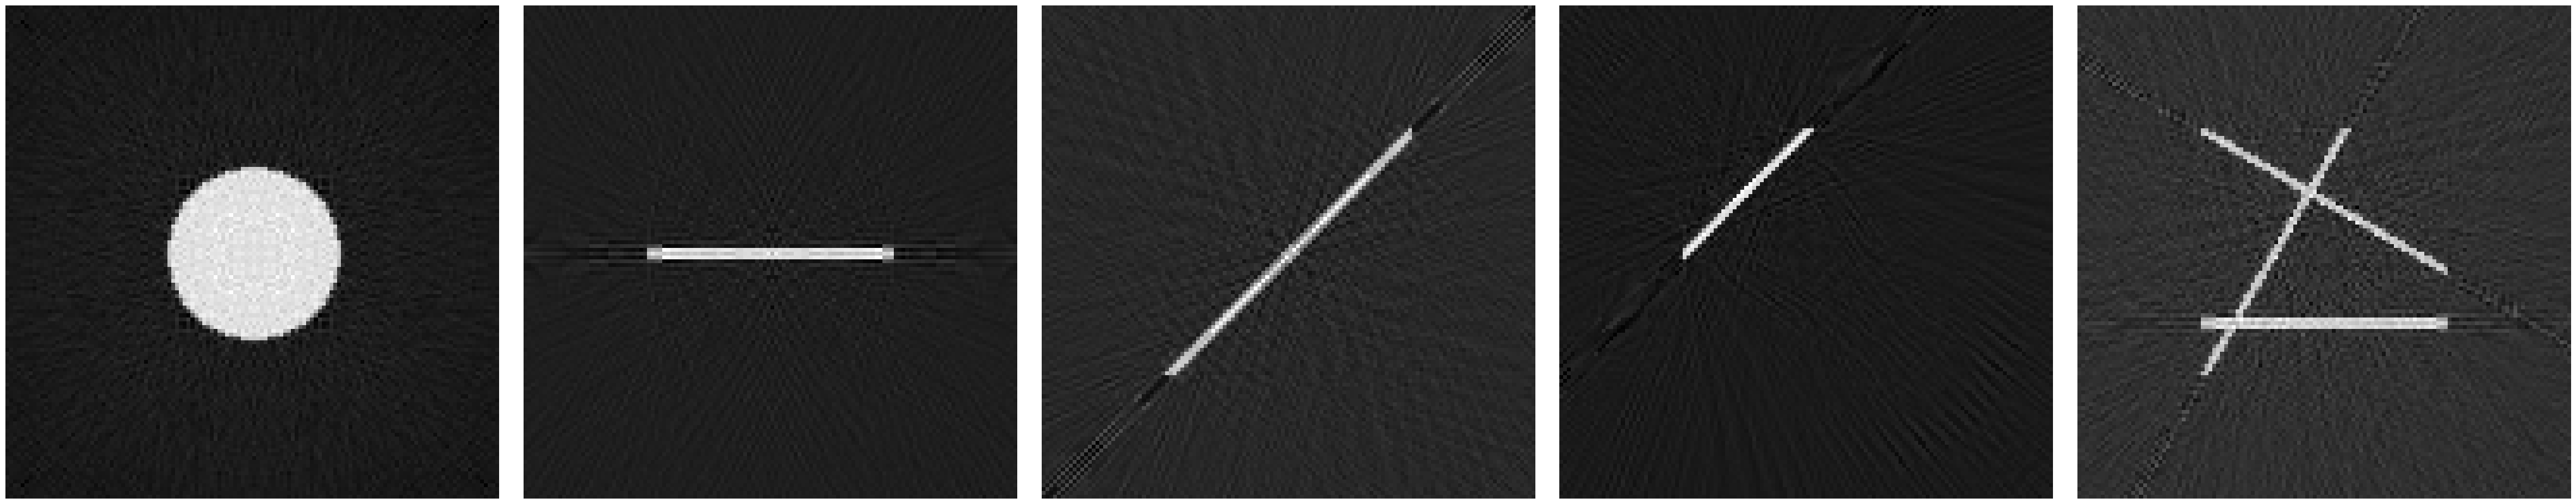

In [ ]:
# Test iradon sur les sinogrammes de l'exercice 4
reconstructions = [iradon(sg) for sg in sinograms]
display_images(reconstructions, lines=1, columns=5)

5.  Tester `iradon` sur les sinogrammes [`brain1.png`][1] et [`brain2.png`][2].

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/brain1.png>
[2]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/brain2.png>

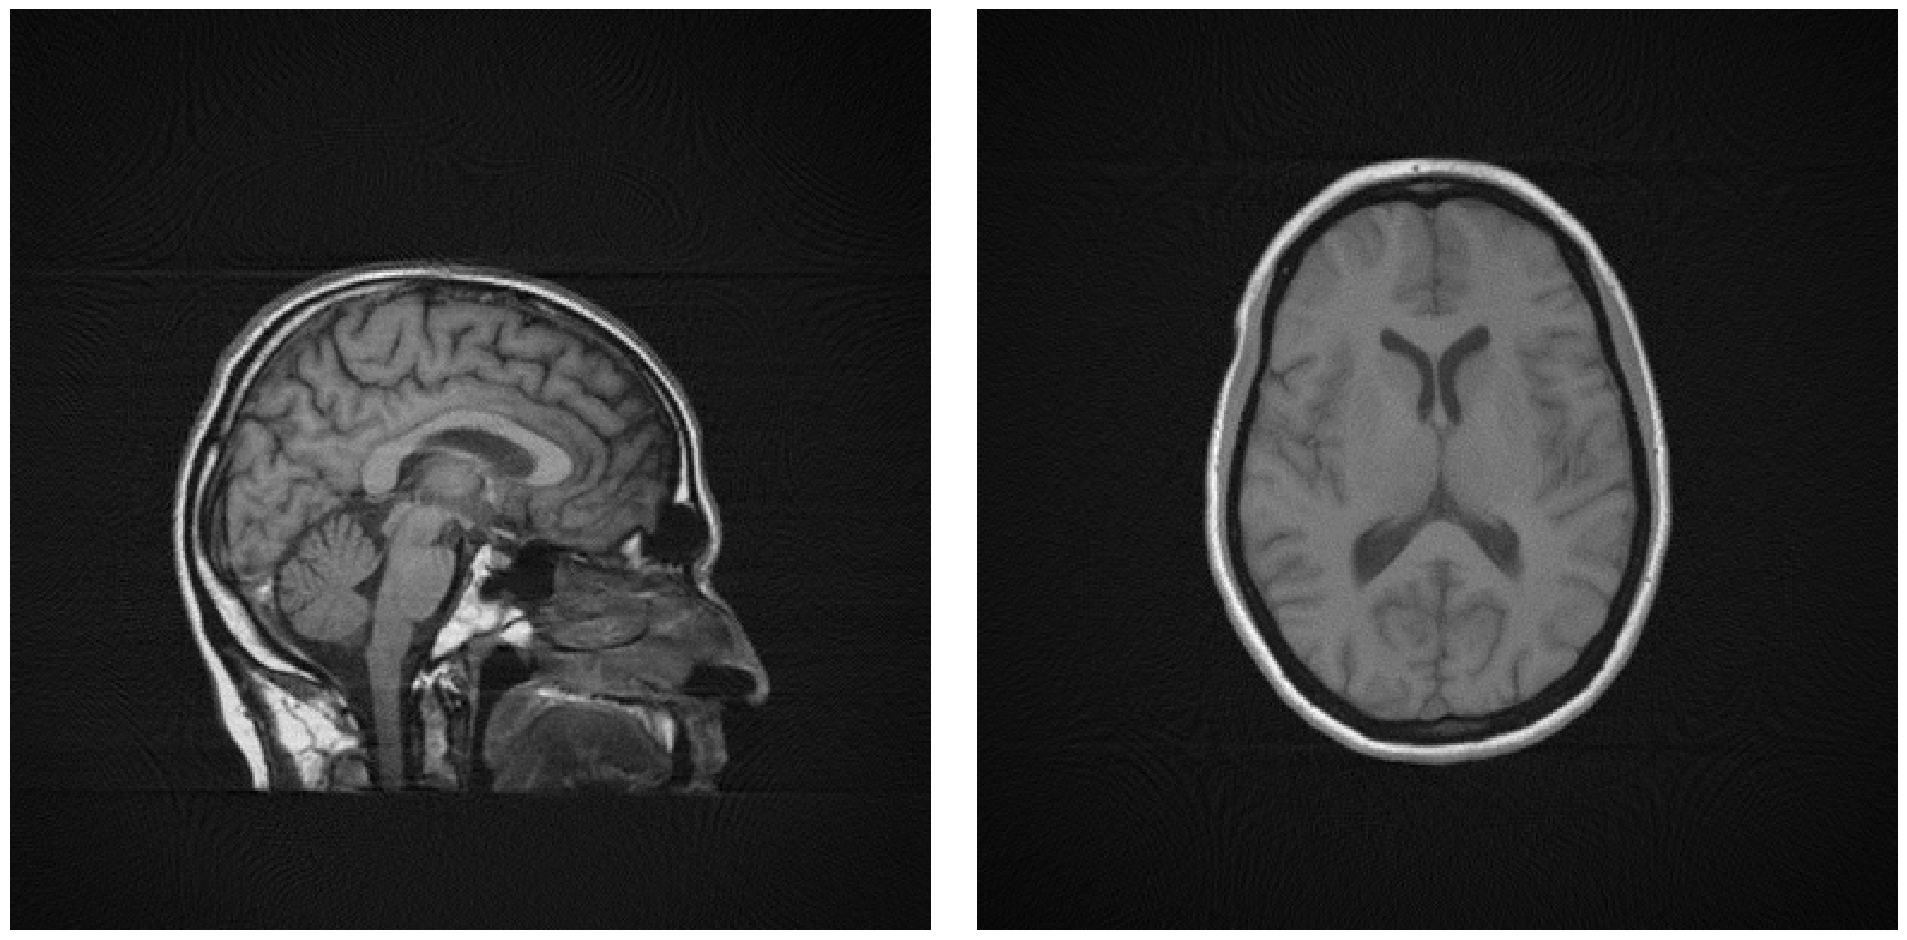

In [ ]:
brain1 = open_image('brain1.png')
brain2 = open_image('brain2.png')
display_images([brain1, brain2], lines=1, columns=2)

recon1 = iradon(brain1)
recon2 = iradon(brain2)
display_images([recon1, recon2], lines=1, columns=2)

6.  Que se passe-t-il si l'on applique un bruit multiplicatif gaussien, centré en $1$ et de variance $0.05$ aux sinogrammes avant la reconstruction ? 
    
    **Indication**
    
    -   Un tel bruit peut être généré grâce à `random.normal(1, 0.05, size = (M, N))`.

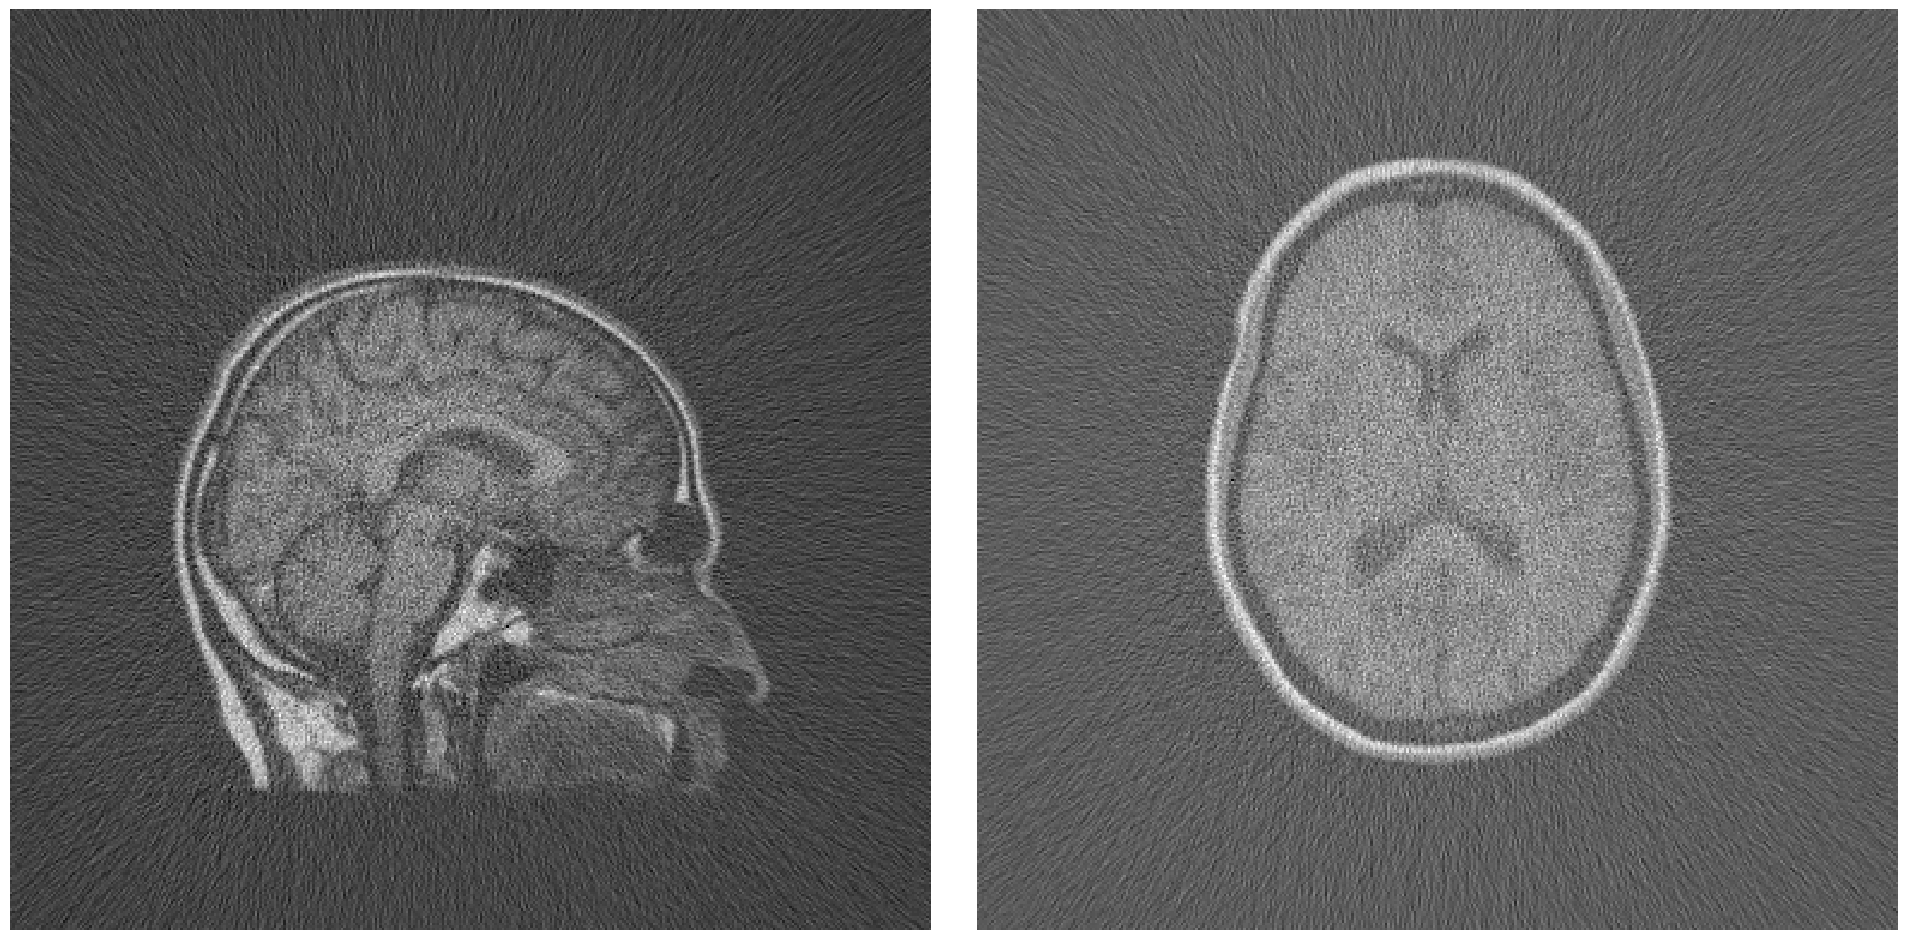

In [ ]:
M_b, N_b = brain1.shape
noise1 = random.normal(1, 0.05, size=(M_b, N_b))
noise2 = random.normal(1, 0.05, size=brain2.shape)

recon1_noisy = iradon(brain1 * noise1)
recon2_noisy = iradon(brain2 * noise2)
display_images([recon1_noisy, recon2_noisy], lines=1, columns=2)

7.  Décrire qualitativement les résultats obtenus.

<div style="color:blue">

**Résultats exercice 5 :**

- **Reconstruction sans bruit** : `iradon` reconstruit fidèlement les images originales à partir de leurs sinogrammes. On retrouve bien les formes géométriques (disques, lignes) et les structures cérébrales des sinogrammes `brain1.png` et `brain2.png`. La formule de rétroprojection filtrée (filtre rampe $|\\lambda|$) est essentielle : sans ce filtre, la rétroprojection seule donnerait une image floue.

- **Reconstruction avec bruit multiplicatif gaussien** ($\\mathcal{N}(1, 0.05)$) : le bruit est amplifié par le filtre rampe $|\\lambda|$ qui valorise les hautes fréquences. On observe une dégradation notable de la qualité de reconstruction : l'image reconstruite présente des artefacts de type « étoile » ou des oscillations haute fréquence. Cela illustre la sensibilité de la transformée de Radon inverse aux perturbations des données, car le filtre rampe est un opérateur mal conditionné (amplification des hautes fréquences). En imagerie médicale réelle, on utilise des filtres rampe régularisés (Shepp-Logan, Hann, etc.) pour atténuer cet effet.

</div>